# FT11 facial expression recognition

Compare MLP, small CNN, ResNet18, and a Paper-based CNN adapted from Singh and Nasoz (2020), DOI [10.1109/CCWC47524.2020.9031283](https://doi.org/10.1109/CCWC47524.2020.9031283). The three original baseline architectures and their starting training settings stay the same. All four models start with random weights.

The tutor's revised requirement is to implement and evaluate at least three meaningfully different methods supported by research. This notebook compares dense connections, a small convolutional design, residual connections, and the selected paper's deeper convolutional design. Dropout alone is a setting change within a method.

The Paper-based CNN follows Figure 4, including its layer sizes and dropout positions. We use a shared training protocol and PyTorch implementation; this is an adaptation, not a claim to reproduce the paper's score. The old dropout-only experiment remains in the saved v5 results. The historical notebook filename is retained so existing links keep working.


## Running the experiment

Use a GPU runtime in Colab if available. Run the cells in order. The training cell starts four fresh models, then the following cells create the comparison tables and figures. Download the ZIP and save your executed notebook before the runtime ends.

Keep the test flag off while reviewing model choices. The report also needs the research discussion, mathematical reasoning, lecture links, contributions, presentation, and Q&A preparation. Graph notes below identify the report section each output supports.


## Terms and a worked example

| Term | Meaning in this notebook |
|---|---|
| MLP | A multilayer perceptron. Fully connected layers use flattened image pixels. |
| CNN | A convolutional neural network. Shared filters learn local image patterns. |
| ResNet18 | An 18-layer residual CNN. Skip connections add an earlier input to a later output. |
| Paper-based CNN | A six-convolution design adapted from Singh and Nasoz Figure 4. It is separate from the small CNN. |
| Logits | The model's seven raw class scores, before softmax. |
| Softmax | Converts logits to scores that sum to one. These are not guaranteed calibrated probabilities. |
| Cross-entropy loss | For the true class, loss is $-\log(p_{true})$. Lower is better on the same evaluation data. |
| Backpropagation | Calculates gradients of loss with respect to trainable weights. |
| Optimizer | Updates weights using gradients. Adam and SGD are available. |
| Parameter | A weight or bias learned during training. More parameters do not guarantee a better model. |
| Hyperparameter | A choice such as learning rate, batch size, dropout rate or epoch limit. |
| Learning rate | Controls the size of an optimizer update. |
| Batch size | Number of images processed before one optimizer update. |
| Epoch | One pass through the selected training images. |
| Random seed | Controls repeatable random choices. Hardware can still change results. |
| Checkpoint | Saved weights and metadata. We select with validation macro-F1, then lower validation loss. |
| Early stopping / patience | Stop after a set number of epochs without improvement under that selection rule. |
| Best epoch / stopped epoch | Epoch of the selected checkpoint / final epoch that ran. They can differ. |
| Convergence | A measured learning curve approaches a plateau. Early stopping does not prove an optimum. |
| Generalization | Performance on examples not used to update the weights. |
| Overfitting | Training improves while validation performance fails to improve or becomes worse. |
| Regularization | A training technique intended to reduce overfitting. Its effect must be measured. |
| Dropout | Randomly sets selected activations to zero during training. It is off during evaluation. |
| Weight decay | Optimizer setting that discourages large weights. |
| Augmentation | Changes training images, for example a random horizontal reflection. Validation images stay unchanged. |
| Support | Number of actual examples of a class in the evaluated split. |
| Accuracy | Correct predictions divided by all evaluated examples. |
| Precision | For one emotion: correct predictions of that emotion divided by all predictions of it. |
| Recall | For one emotion: correct predictions of that emotion divided by its actual examples. |
| F1 | Harmonic mean: $F1 = 2PR/(P+R)$. The score is zero when both inputs are zero. |
| Macro-F1 | Mean of the seven class F1 scores. Each emotion has equal weight. |
| Confusion matrix | Rows are actual emotions; columns are predicted emotions. The diagonal contains correct predictions. |
| Gap | Training diagnostic accuracy minus validation accuracy, in percentage points. A small gap alone does not prove a useful model. |
| Inference | Run the saved model to predict labels, without weight updates. |
| Latency / throughput | Time for one prediction / images processed per second in a batch. |
| Transfer learning / fine-tuning | Reuse previously learned knowledge / continue updating an already trained model for a task. All four models here start fresh. |
| Frozen backbone / head | Feature layers that are not updated / the final seven-class classifier. |
| Standard deviation (SD) | Variation between repeated runs. One seed cannot measure seed variation. |

**Example:** There are 10 actual Happy images. The model predicts Happy for 8 images, and 6 are correct. Precision = 6/8 = 0.75, recall = 6/10 = 0.60, and F1 = 0.667. If the true-class softmax score is 0.8, cross-entropy is about 0.223; if it is 0.2, loss is about 1.609. These are examples, not FT11 results.

Accuracy can hide weak results on rare emotions. Use macro-F1 and the class table together. A prediction label describes the dataset expression class; it does not establish a person's internal emotional state.


## Packages

Install missing packages, then import the libraries and check the device. The install cell keeps the runtime's existing PyTorch and torchvision versions. `cuda_available` reports NVIDIA CUDA support; the selected device can also be MPS or CPU.


In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "kagglehub": "kagglehub",
    "numpy": "numpy",
    "PIL": "Pillow",
    "matplotlib": "matplotlib",
}
missing_packages = [
    package for module, package in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing_packages]
    )
print("Missing lightweight packages installed:", missing_packages or "none")

Missing lightweight packages installed: none


## Shared training settings

These are FT11's documented starting settings. The baseline architectures and the shared Adam/learning-rate/batch settings are unchanged. The custom MLP and small CNN have no universal official default.

`MAX_EPOCHS = 20` caps the passes through all training images. `PATIENCE = 3` stops a run after three epochs without a higher validation macro-F1; lower validation loss breaks an exact F1 tie. The selected checkpoint can be earlier than the final epoch.

Figure 4 and the paper text specify two dropout layers at 0.2. That fixed architecture choice belongs to the Paper-based CNN. The paper reports batch size 512 and 10 epochs, but does not identify its optimizer, learning rate, initialization scheme, or random seed. For this comparison, the Paper-based CNN uses the same FT11 optimizer, batch size, budget, and stopping rule as the baselines. It does not claim the paper's reported score.

Report use: Solutions, evaluation, and discussions / methods and training setup.


In [2]:
from pathlib import Path

SEED = 42                       # Repeat initialization and batch order for this experiment
VALIDATION_FRACTION = 0.15
EXPERIMENT_NAME = "three-baselines-and-paper-cnn"
OPTIMIZER_NAME = "Adam"          # "Adam" or "SGD"
MOMENTUM = 0.9                   # Used by SGD
LEARNING_RATE = 0.001           # Adam step-size setting shared by the four models
WEIGHT_DECAY = 0.0
BATCH_SIZE = 64                 # Images per weight update; the final batch can be smaller
MAX_EPOCHS = 20                 # Maximum full passes through the training split
PATIENCE = 3                    # Consecutive epochs without a better validation checkpoint
PAPER_DROPOUT_RATE = 0.2         # Both dropout layers in the selected paper design
RUN_FINAL_TEST = False           # Use only after model and setting decisions are fixed

DATASET_HANDLE = "msambare/fer2013"
EXPECTED_V1_DATA_FINGERPRINT = "d67be25b0158b2017c0f4ad4eca68b8632bd9ec66bb579cf2de8224fe1eabf82"
OUTPUT_BASE = Path("/content/fer2013_colab_runs" if Path("/content").is_dir() else "fer2013_colab_runs")
NOTEBOOK_FILE = "FT11_Option1_Baselines.ipynb"
NOTEBOOK_REVISION = "four-methods-paper-cnn-v5"
NOTEBOOK_TEMPLATE_SOURCE_SHA256 = "7c117db1a21c7a412394124cde4e4b70132cd5bfccc82f6dff0a9599665f04b3"

if OPTIMIZER_NAME not in {"Adam", "SGD"}:
    raise ValueError("Choose Adam or SGD.")
if not 0.05 <= VALIDATION_FRACTION <= 0.40:
    raise ValueError("Validation fraction must be from 0.05 to 0.40.")
if not isinstance(SEED, int) or isinstance(SEED, bool) or not 0 <= SEED < 2**32:
    raise ValueError("Use an integer seed from 0 to 2**32 - 1.")
if any(not isinstance(v, int) or isinstance(v, bool) or v < 1 for v in (BATCH_SIZE, MAX_EPOCHS, PATIENCE)):
    raise ValueError("Batch size, epoch limit and patience must be positive integers.")
if LEARNING_RATE <= 0 or WEIGHT_DECAY < 0 or not 0 < PAPER_DROPOUT_RATE < 1:
    raise ValueError("Check learning rate, weight decay and dropout rate.")

## Runtime

Import the libraries and select CUDA, MPS or CPU. The printed versions and device describe this run. Report use: methods / software and hardware.


In [3]:
import platform
import random
import time
import uuid
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import PIL
import torch
import torch.nn as nn
import torchvision
from PIL import Image, UnidentifiedImageError
from torch.utils.data import DataLoader, Dataset

try:
    import google.colab
    IN_COLAB = True
except ModuleNotFoundError:
    IN_COLAB = False

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else
    "mps" if torch.backends.mps.is_available() else "cpu"
)
print({
    "runtime": "Google Colab" if IN_COLAB else "Python",
    "device": str(DEVICE),
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cuda_available": torch.cuda.is_available(),
})
if DEVICE.type == "cpu":
    print("CPU detected. A GPU runtime can reduce the training time, especially for ResNet18.")

{'runtime': 'Google Colab', 'device': 'cpu', 'python': '3.13.18', 'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'cuda_available': False}
CPU detected. A GPU runtime can reduce the training time, especially for ResNet18.


## FER2013 image folders

KaggleHub downloads `msambare/fer2013`. Use its returned path to find the labelled train and test folders. Record the content fingerprint; record a dataset version only when the returned path verifies it. No archive upload or repository clone is needed.

Report use: Introduction / dataset source, and methods / preprocessing.


In [4]:
import hashlib
import json
import re
import tempfile

LABELS = ("angry", "disgust", "fear", "happy", "sad", "surprise", "neutral")
IMAGE_SIZE = (48, 48)
IMAGE_EXTENSIONS = {".bmp", ".jpeg", ".jpg", ".png", ".tif", ".tiff", ".webp"}
PREPROCESSING = {
    "size": [48, 48],
    "channels": 1,
    "conversion": "Pillow convert('L')",
    "resize": "Pillow bilinear",
    "scale": "float32 pixels divided by 255",
    "augmentation": "none",
}

import kagglehub

# Download latest version
path = kagglehub.dataset_download("msambare/fer2013")
print("Path to dataset files:", path)
DATA_LABEL = "FER2013"

DATA_ROOT = Path(path).expanduser()
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"
if not TRAIN_DIR.is_dir() or not TEST_DIR.is_dir():
    raise FileNotFoundError(f"Expected train/ and test/ folders under {DATA_ROOT}.")

def resolve_version_from_path(download_path, handle):
    parts = Path(download_path).parts
    owner, slug = handle.split("/", 1)
    for index in range(len(parts) - 4):
        if (
            parts[index] == "datasets"
            and parts[index + 1:index + 3] == (owner, slug)
            and parts[index + 3] == "versions"
            and parts[index + 4].isdigit()
        ):
            return parts[index + 4]
    return None

RESOLVED_VERSION = resolve_version_from_path(path, DATASET_HANDLE)
VERSION_VERIFIED = RESOLVED_VERSION is not None
SOURCE_ID = (
    f"{DATASET_HANDLE}/versions/{RESOLVED_VERSION}"
    if VERSION_VERIFIED
    else f"{DATASET_HANDLE}/latest-unverified"
)
SOURCE_PROVENANCE = {
    "requested_handle": DATASET_HANDLE,
    "request": "latest (unversioned)",
    "resolved_version": RESOLVED_VERSION,
    "version_verified_from_returned_path": VERSION_VERIFIED,
    "source_id_for_manifest": SOURCE_ID,
    "download_returned_path": str(path),
    "download_time_utc": datetime.now(timezone.utc).isoformat(),
}
print({
    "source_id": SOURCE_ID,
    "version_verified": VERSION_VERIFIED,
    "data_root": DATA_ROOT,
})

Using Colab cache for faster access to the 'fer2013' dataset.
Path to dataset files: /kaggle/input/fer2013
{'source_id': 'msambare/fer2013/latest-unverified', 'version_verified': False, 'data_root': PosixPath('/kaggle/input/fer2013')}


## Split and duplicate checks

All four models use the same audited rows. Keep same-label duplicate groups in one development split. Exclude training copies of source-test images and conflicting-label development groups. Preserve source-test rows for final evaluation. The audit records exclusions without deleting source files.

The earlier saved content had 23,743 training, 4,190 validation, 7,178 source-test, and 776 excluded development images. The scan checks the current content rather than forcing these counts. The source test is audited for overlap but is not scored during model selection.

The next table shows class counts. Its image panel takes two training examples per emotion; use it to introduce the dataset, not to measure performance.

Report use: Introduction / data, and methods / split and duplicate policy.


In [5]:
def canonical_label(folder_name):
    label = folder_name.strip().casefold()
    if label not in LABELS:
        raise ValueError(f"Unknown class folder: {folder_name}")
    return label

def scan_split(directory, source_split):
    directory = Path(directory)
    if not directory.is_dir():
        raise FileNotFoundError(f"ImageFolder directory does not exist: {directory}")
    class_directories = sorted(item for item in directory.iterdir() if item.is_dir())
    found = {canonical_label(item.name) for item in class_directories}
    missing = sorted(set(LABELS) - found)
    if missing:
        raise ValueError(f"{directory} is missing class folders: {', '.join(missing)}")

    records = []
    unassigned_files = []
    for class_directory in class_directories:
        label = canonical_label(class_directory.name)
        for file_path in sorted(class_directory.rglob("*")):
            if not file_path.is_file():
                continue
            row = {
                "source_split": source_split,
                "relative_path": file_path.relative_to(directory).as_posix(),
                "label": label,
                "class_id": LABELS.index(label),
                "image_sha256": None,
                "split": "excluded",
                "exclusion_reason": None,
            }
            if file_path.suffix.casefold() not in IMAGE_EXTENSIONS:
                row["exclusion_reason"] = "unsupported_file_type"
                row["audit_detail"] = file_path.suffix or "no file extension"
                records.append(row)
                continue
            try:
                with Image.open(file_path) as image:
                    pixels = np.asarray(
                        image.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR),
                        dtype=np.uint8,
                    )
                row["image_sha256"] = hashlib.sha256(pixels.tobytes()).hexdigest()
            except (OSError, UnidentifiedImageError, ValueError) as error:
                row["exclusion_reason"] = "unreadable_image"
                row["audit_detail"] = f"{type(error).__name__}: {error}"
            records.append(row)

    for file_path in sorted(directory.iterdir()):
        if file_path.is_file():
            unassigned_files.append(file_path.name)
    return records, unassigned_files

def stratified_group_split(records_by_hash, seed, validation_fraction):
    validation_hashes = set()
    class_summary = {}
    for class_id, label in enumerate(LABELS):
        group_hashes = sorted(
            image_hash for image_hash, group in records_by_hash.items()
            if group[0]["class_id"] == class_id
        )
        if not group_hashes:
            class_summary[label] = {
                "train_records": 0, "validation_records": 0, "validation_groups": 0
            }
            continue
        sizes = {image_hash: len(records_by_hash[image_hash]) for image_hash in group_hashes}
        total_records = sum(sizes.values())
        target = max(1, int(round(total_records * validation_fraction)))
        if len(group_hashes) == 1:
            class_summary[label] = {
                "train_records": total_records,
                "validation_records": 0,
                "validation_groups": 0,
                "note": "Only one exact-image group exists; it stays in train.",
            }
            continue
        rng = np.random.default_rng(np.random.SeedSequence([seed, class_id]))
        order = [group_hashes[index] for index in rng.permutation(len(group_hashes))]
        chosen = []
        count = 0
        for index, image_hash in enumerate(order):
            if len(order) - index <= 1:
                break
            proposed = count + sizes[image_hash]
            if not chosen or abs(proposed - target) <= abs(count - target):
                chosen.append(image_hash)
                count = proposed
            elif count >= target:
                break
        validation_hashes.update(chosen)
        class_summary[label] = {
            "train_records": total_records - count,
            "validation_records": count,
            "validation_groups": len(chosen),
            "target_validation_records": target,
        }
    return validation_hashes, class_summary

def count_rows(records, split_key="split"):
    result = {}
    for split_name in ("train", "validation", "test", "excluded"):
        selected = [row for row in records if row.get(split_key) == split_name]
        result[split_name] = {
            "records": len(selected),
            "classes": {
                label: sum(row.get("label") == label for row in selected)
                for label in LABELS
            },
        }
    return result

def stable_manifest_hash(payload):
    stable_payload = {
        key: value for key, value in payload.items()
        if key not in {"generated_at_utc", "manifest_sha256"}
    }
    canonical = json.dumps(stable_payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(canonical).hexdigest()

def build_manifest(train_dir, test_dir, source_id, seed=42, validation_fraction=0.15):
    if not 0.05 <= validation_fraction <= 0.4:
        raise ValueError("validation_fraction must be between 0.05 and 0.40.")
    train_records, train_unassigned = scan_split(train_dir, "train")
    test_records, test_unassigned = scan_split(test_dir, "test")
    records = train_records + test_records
    grouped = defaultdict(list)
    for row in records:
        if row.get("image_sha256"):
            grouped[row["image_sha256"]].append(row)

    conflicts = []
    cross_source_duplicates = []
    eligible_train_groups = {}
    for image_hash, group in sorted(grouped.items()):
        labels = sorted({row["label"] for row in group})
        sources = {row["source_split"] for row in group}
        paths = [f"{row['source_split']}/{row['relative_path']}" for row in group]
        if len(labels) > 1:
            conflicts.append({
                "image_sha256": image_hash,
                "labels": labels,
                "paths": paths,
                "source_test_rows_retained": sum(row["source_split"] == "test" for row in group),
                "source_train_rows_excluded": sum(row["source_split"] == "train" for row in group),
            })
            for row in group:
                if row["source_split"] == "test":
                    row["split"] = "test"
                else:
                    row["exclusion_reason"] = "exact_duplicate_has_conflicting_labels"
            continue
        if sources == {"train", "test"}:
            cross_source_duplicates.append({
                "image_sha256": image_hash, "label": labels[0], "paths": paths
            })
            for row in group:
                row["split"] = "test" if row["source_split"] == "test" else "excluded"
                if row["source_split"] == "train":
                    row["exclusion_reason"] = "exact_duplicate_also_exists_in_source_test"
            continue
        if sources == {"test"}:
            for row in group:
                row["split"] = "test"
            continue
        eligible_train_groups[image_hash] = group

    validation_hashes, class_summary = stratified_group_split(
        eligible_train_groups, seed, validation_fraction
    )
    for image_hash, group in eligible_train_groups.items():
        split_name = "validation" if image_hash in validation_hashes else "train"
        for row in group:
            row["split"] = split_name

    for row in records:
        if row.get("exclusion_reason") is None:
            row.pop("exclusion_reason", None)
    records.sort(key=lambda row: (row["source_split"], row["relative_path"].casefold()))
    duplicate_group_sizes = [len(group) for group in grouped.values() if len(group) > 1]
    payload = {
        "schema_version": 1,
        "source_id": source_id,
        "label_order": list(LABELS),
        "preprocessing": PREPROCESSING,
        "split_settings": {
            "seed": seed,
            "validation_fraction": validation_fraction,
            "source_test": "kept as supplied and excluded from model selection; unreadable or unsupported files remain listed as excluded",
        },
        "duplicate_policy": {
            "hash": "SHA-256 of the grayscale 48x48 pixels used by the models",
            "same_label_source_train_duplicates": "keep all rows in one split group",
            "train_and_source_test_duplicate": "keep source-test rows in test; exclude source-train copies",
            "conflicting_label_duplicate": "retain every source-test row in test; exclude matching source-train rows; exclude conflicting source-train-only groups from model splits; preserve and list all source paths",
            "unreadable_or_unsupported": "preserve the source file and list it as excluded with a reason",
        },
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "class_split_summary": class_summary,
        "duplicate_audit": {
            "duplicate_groups": len(duplicate_group_sizes),
            "records_in_duplicate_groups": sum(duplicate_group_sizes),
            "largest_duplicate_group": max(duplicate_group_sizes, default=1),
            "train_test_duplicate_groups": cross_source_duplicates,
            "conflicting_label_duplicate_groups": conflicts,
        },
        "unassigned_root_files": {"train": train_unassigned, "test": test_unassigned},
        "counts": count_rows(records),
        "source_counts": {
            source_split: {
                "records": sum(row["source_split"] == source_split for row in records),
                "classes": {
                    label: sum(
                        row["source_split"] == source_split and row["label"] == label
                        for row in records
                    )
                    for label in LABELS
                },
            }
            for source_split in ("train", "test")
        },
        "records": records,
    }
    payload["manifest_sha256"] = stable_manifest_hash(payload)
    return payload

def source_data_fingerprint(records):
    stable_rows = [
        (
            row["source_split"], row["relative_path"], row["label"], row.get("image_sha256")
        )
        for row in sorted(
            records, key=lambda row: (row["source_split"], row["relative_path"].casefold())
        )
    ]
    canonical = json.dumps(stable_rows, ensure_ascii=False, separators=(",", ":")).encode()
    return hashlib.sha256(canonical).hexdigest()

def split_assignment_fingerprint(records):
    stable_rows = [
        (
            row["source_split"], row["relative_path"], row["label"],
            row.get("image_sha256"), row["split"], row.get("exclusion_reason"),
        )
        for row in sorted(
            records, key=lambda row: (row["source_split"], row["relative_path"].casefold())
        )
    ]
    canonical = json.dumps(stable_rows, ensure_ascii=False, separators=(",", ":")).encode()
    return hashlib.sha256(canonical).hexdigest()

manifest = build_manifest(
    TRAIN_DIR,
    TEST_DIR,
    source_id=SOURCE_ID,
    seed=SEED,
    validation_fraction=VALIDATION_FRACTION,
)
DATA_FINGERPRINT = source_data_fingerprint(manifest["records"])
SPLIT_ASSIGNMENT_FINGERPRINT = split_assignment_fingerprint(manifest["records"])
SOURCE_PROVENANCE["data_fingerprint"] = DATA_FINGERPRINT
SOURCE_PROVENANCE["split_assignment_fingerprint"] = SPLIT_ASSIGNMENT_FINGERPRINT
SOURCE_PROVENANCE["manifest_sha256"] = manifest["manifest_sha256"]

if DATA_FINGERPRINT == EXPECTED_V1_DATA_FINGERPRINT:
    print("Data fingerprint matches the saved v1 source content.")
else:
    print("Data fingerprint differs from saved v1 content. This run uses an isolated output folder.")
print("Resolved source ID:", SOURCE_ID)
print("Resolved version verified:", VERSION_VERIFIED)
print("Manifest SHA-256:", manifest["manifest_sha256"])
print("Source counts:", json.dumps(manifest["source_counts"], indent=2))
print("Split counts:", json.dumps(manifest["counts"], indent=2))
print("Duplicate groups:", manifest["duplicate_audit"]["duplicate_groups"])
print("Train/test duplicate groups:", len(manifest["duplicate_audit"]["train_test_duplicate_groups"]))
print("Conflicting-label groups:", len(manifest["duplicate_audit"]["conflicting_label_duplicate_groups"]))

Data fingerprint matches the saved v1 source content.
Resolved source ID: msambare/fer2013/latest-unverified
Resolved version verified: False
Manifest SHA-256: 457b2e20af6522b9dcb775abb25b8c3f558db65f7ff0c207051d42ca975e8546
Source counts: {
  "train": {
    "records": 28709,
    "classes": {
      "angry": 3995,
      "disgust": 436,
      "fear": 4097,
      "happy": 7215,
      "sad": 4830,
      "surprise": 3171,
      "neutral": 4965
    }
  },
  "test": {
    "records": 7178,
    "classes": {
      "angry": 958,
      "disgust": 111,
      "fear": 1024,
      "happy": 1774,
      "sad": 1247,
      "surprise": 831,
      "neutral": 1233
    }
  }
}
Split counts: {
  "train": {
    "records": 23743,
    "classes": {
      "angry": 3284,
      "disgust": 327,
      "fear": 3374,
      "happy": 6083,
      "sad": 4052,
      "surprise": 2449,
      "neutral": 4174
    }
  },
  "validation": {
    "records": 4190,
    "classes": {
      "angry": 580,
      "disgust": 58,
      "fear"

## Class counts and training examples

Read the counts to check class imbalance. The panel shows two training images per available emotion. Report use: Introduction / dataset, and methods / split.


| Split | Total | Angry | Disgust | Fear | Happy | Sad | Surprise | Neutral |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Train | 23,743 | 3,284 | 327 | 3,374 | 6,083 | 4,052 | 2,449 | 4,174 |
| Validation | 4,190 | 580 | 58 | 596 | 1,073 | 715 | 432 | 736 |
| Test | 7,178 | 958 | 111 | 1,024 | 1,774 | 1,247 | 831 | 1,233 |
| Excluded | 776 | 131 | 51 | 127 | 59 | 63 | 290 | 55 |

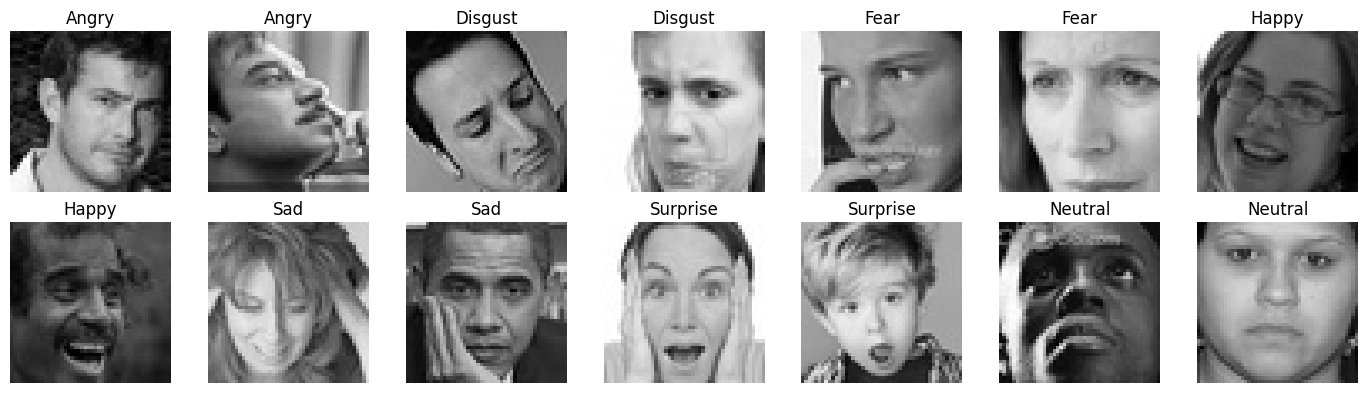

In [6]:
from IPython.display import display, Markdown

count_lines = [
    "| Split | Total | " + " | ".join(label.capitalize() for label in LABELS) + " |",
    "|---|" + "---:|" * (len(LABELS) + 1),
]
for split_name in ("train", "validation", "test", "excluded"):
    values = manifest["counts"][split_name]["classes"]
    count_lines.append(
        f"| {split_name.capitalize()} | {manifest['counts'][split_name]['records']:,} | "
        + " | ".join(f"{values[label]:,}" for label in LABELS)
        + " |"
    )
display(Markdown("\n".join(count_lines)))

sample_rows = []
for label in LABELS:
    candidates = [
        row for row in manifest["records"]
        if row["split"] == "train" and row["label"] == label
    ]
    sample_rows.extend(candidates[:2])

fig, axes = plt.subplots(2, 7, figsize=(14, 4))
for axis, row in zip(axes.flat, sample_rows):
    with Image.open(TRAIN_DIR / row["relative_path"]) as image:
        shown = image.convert("L").resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    axis.imshow(shown, cmap="gray", vmin=0, vmax=255)
    axis.set_title(row["label"].capitalize())
    axis.axis("off")
for axis in axes.flat[len(sample_rows):]:
    axis.axis("off")
fig.tight_layout()
plt.show()

## Model designs

| Model | Processing | Design to explain |
|---|---|---|
| MLP baseline | Flatten 48x48 pixels, 128 ReLU units, seven logits | Fully connected learning from pixels |
| Small CNN baseline | Three Conv/ReLU/pool stages with 6, 16, 32 channels, then 64 ReLU units | Local filters, shared weights and pooling; adapted from the lab pattern |
| ResNet18 baseline | Torchvision residual architecture, one input channel, seven outputs | Skip connections in a deeper CNN; `weights=None` |
| Paper-based CNN | Six 3x3 Conv/ReLU layers with 128 channels, three pools, two dropout layers, 1,024-unit dense layer | A deeper paired-convolution design from the selected research paper |

The first three architectures remain the same. The Paper-based CNN has different depth, filters, pooling and classifier size from the small CNN. It is not the old dropout-only configuration and does not load baseline CNN weights.

Lecture 2 covers feedforward learning, CNNs, dropout and residual connections. Exact FT11 sizes and the paper's architecture are design choices. Report use: Background theory, and solutions / model architecture.


## Mathematical reasoning

Use these relationships with the measured results. Write the report explanation in the team's own words.

| Concept | Relationship | What to explain |
|---|---|---|
| Convolution size | $H_{out}=\lfloor(H+2P-K)/S\rfloor+1$ for dilation 1 | Valid convolutions reduce spatial size; pooling reduces it further. |
| Conv parameters | $(K_h K_w C_{in}+1)C_{out}$ with biases | Weight sharing limits the parameter count. |
| Dense parameters | $(n_{in}+1)n_{out}$ | Flatten size and dense width affect model size. |
| Loss | $p_k=e^{z_k}/\sum_j e^{z_j}$; $L=-\log p_{true}$ | Higher probability for the correct class lowers cross-entropy. Pass logits directly to PyTorch cross-entropy. |
| Learning | $\partial L/\partial z_k=p_k-1[k=true]$ | Backpropagation calculates gradients. Adam uses gradient history to update weights. |
| Residual block | $y=F(x)+x$ for matching shapes | A shortcut gives information and gradients another path. |
| F1 | $2TP/(2TP+FP+FN)$ | Precision and recall both matter. Macro-F1 averages all seven classes equally. |

Small CNN sizes: `48 -> 44 -> 22 -> 18 -> 9 -> 5 -> 2`, then `32*2*2 = 128` flattened values. Parameters: `156 + 2,416 + 12,832 + 8,256 + 455 = 24,115`.

Paper-based CNN sizes from Figure 4: `48 -> 46 -> 44 -> 21 -> 19 -> 17 -> 8 -> 6 -> 4 -> 2`, then `128*2*2 = 512` flattened values, a 1,024-unit dense layer and seven logits. The matching parameter total is **1,271,687**.

Course links: Lecture 2 p52 adaptive step sizes/Adam; pp55-59 image structure, convolution, sharing and pooling; p61 ReLU/dropout/augmentation; p63 residual connections. Lab 1 shows classification and CNN training; Lab 2 covers gradients.


## Selected paper: problem, method and limits

Singh and Nasoz study seven-class facial expression recognition on FER2013. Pose, lighting, occlusion and similar expressions make classification difficult. Their implemented CNN uses six convolutions, three pooling layers, two dropout layers, and two dense layers. They report 61.7% test accuracy, with Fear and Sad among the difficult classes.

The paper also reports 99.64% training accuracy and identifies overfitting. Its dropout layers did not remove that problem. It illustrates face detection, illumination correction and landmark extraction, and proposes further preprocessing and augmentation. The reported 61.7% classification result is described as using the CNN without those additions; the paper does not supply a controlled improvement result for them.

| Detail | Paper evidence | This notebook |
|---|---|---|
| Layers, widths, shapes and parameter counts | Figure 4, PDF p3 / printed p326 | Matches the six-convolution layout and total 1,271,687 parameters. |
| Conv kernels, stride, padding and biases | 48->46->44 etc.; first layer 1,280 parameters | 3x3 valid kernels, stride 1 and biases inferred from the figure's shapes/counts. |
| Pooling | Text states 3x3/stride 2 twice, then 2x2/stride 2 | Same sizes and order as Figure 4. |
| Dropout | Text states 0.2 twice; Figure 4 shows positions | Elementwise dropout after pool 2 and dense ReLU. |
| Output | Seven-output softmax in Keras | Seven logits; PyTorch CrossEntropyLoss computes log-softmax internally. Apply softmax only when probabilities are needed. |
| Training | Reports batch 512 and 10 epochs; optimizer/LR/seed/initializer not specified | Shared FT11 Adam 0.001, batch 64, seed 42, random PyTorch initialization, cap 20, patience 3. |
| Evaluation | Paper reports a FER2013 test score | FT11 uses its audited split and validation selection. Keep the test separate until choices are fixed. |

The comparison tests this paper-based architecture under FT11's shared protocol. It does not isolate the effect of a single change or claim the paper's original score.

Report use: Background theory / research source, and solutions / implementation differences.


In [7]:
# Keep the source and adaptation choices with every exported experiment.
PAPER_METHOD = {
    "label": "Paper-based CNN",
    "authors": ["Shekhar Singh", "Fatma Nasoz"], "year": 2020,
    "title": "Facial Expression Recognition with Convolutional Neural Networks",
    "doi": "10.1109/CCWC47524.2020.9031283",
    "architecture_reference": "Figure 4, PDF page 3, printed page 326",
    "architecture_parameter_count": 1271687,
    "stated_design": {"conv_layers": 6, "conv_channels": [128]*6,
        "pool_kernels": [3, 3, 2], "pool_strides": [2, 2, 2],
        "dense_hidden_units": 1024, "output_classes": 7, "dropout_rates": [0.2, 0.2]},
    "inferred_from_figure": ["3x3 convolutions", "stride 1", "padding 0", "convolution and dense biases"],
    "paper_reported_training": {"batch_size": 512, "epochs": 10},
    "unspecified_in_paper": ["optimizer", "learning rate", "random seed", "weight initialization"],
    "ft11_adaptations": ["PyTorch instead of Keras/TensorFlow", "logits with CrossEntropyLoss instead of explicit softmax",
        "shared Adam 0.001, batch 64, epoch cap 20 and patience 3", "fixed seed and PyTorch random initialization",
        "FT11 audited split and validation macro-F1 checkpoint selection"],
    "claim": "research-based adaptation; not a novel algorithm or exact score reproduction",
}


## Build and check the models

The next block defines the three baselines and Paper-based CNN. A two-image input checks that each model returns seven scores. Parameter counts describe architecture size, not accuracy. Report use: Background theory / architectures, and solutions / implementation.


In [8]:
from torchvision.models import resnet18

BASELINE_MODEL_IDS = ("mlp", "cnn", "resnet18")
MODEL_IDS = (*BASELINE_MODEL_IDS, "paper_cnn")

class MLP(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),  # [batch, 1, 48, 48] becomes [batch, 2304].
            nn.Linear(48 * 48, 128),  # All pixels feed the 128 hidden units.
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

    def forward(self, values):
        return self.layers(values)

class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5),  # 1x48x48 -> 6x44x44; shared local filters.
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(6, 16, kernel_size=5),  # After pooling: 6x22x22 -> 16x18x18.
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=5),  # After pooling: 16x9x9 -> 32x5x5.
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 2 * 2, 64),  # Final pooling leaves 128 values per image.
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, values):
        return self.classifier(self.features(values))


class PaperCNN(nn.Module):
    """PyTorch adaptation of Singh and Nasoz (2020), Figure 4, PDF page 3."""

    def __init__(self, num_classes=7):
        super().__init__()
        self.features = nn.Sequential(
            # Figure 4: two valid 3x3 convolutions, all 128 output channels.
            nn.Conv2d(1, 128, kernel_size=3),  # 48 -> 46; 1,280 parameters.
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),  # 46 -> 44.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),  # 44 -> 21.
            nn.Conv2d(128, 128, kernel_size=3),  # 21 -> 19.
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),  # 19 -> 17.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=3, stride=2),  # 17 -> 8.
            nn.Dropout(PAPER_DROPOUT_RATE),  # Figure 4 places dropout after pool 2.
            nn.Conv2d(128, 128, kernel_size=3),  # 8 -> 6.
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3),  # 6 -> 4.
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),  # 4 -> 2.
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),  # [batch, 128, 2, 2] -> [batch, 512]; no learned weights.
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Dropout(PAPER_DROPOUT_RATE),  # Second paper dropout layer.
            nn.Linear(1024, num_classes),  # Raw logits; CrossEntropyLoss handles log-softmax.
        )

    def forward(self, values):
        return self.classifier(self.features(values))

def base_model(model_id, num_classes=7):
    if model_id == "mlp":
        return MLP(num_classes)
    if model_id == "cnn":
        return SmallCNN(num_classes)
    if model_id == "paper_cnn":
        return PaperCNN(num_classes)
    if model_id == "resnet18":
        # Keep the baseline initialization and grayscale/seven-output changes.
        model = resnet18(weights=None)
        model.conv1 = nn.Conv2d(
            1, 64, kernel_size=7, stride=2, padding=3, bias=False
        )
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        return model
    raise ValueError(f"Unknown model id: {model_id}")

def trainable_parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

def make_model(model_id, config):
    model = base_model(model_id)
    if model_id == "paper_cnn":
        # The paper dropouts are already inside PaperCNN; do not insert another one.
        if config.get("dropout", PAPER_DROPOUT_RATE) != PAPER_DROPOUT_RATE:
            raise ValueError("PaperCNN uses the recorded Figure 4 dropout rate.")
    elif config.get("dropout", 0.0) != 0.0:
        raise ValueError("Keep the three baselines unchanged. Historical dropout runs are in v5.")
    return model

for model_id in MODEL_IDS:
    model = make_model(model_id, {})
    model.eval()
    with torch.inference_mode():
        output = model(torch.zeros(2, 1, 48, 48))
    assert tuple(output.shape) == (2, 7), "Each model must return seven logits per image."
    if model_id == "paper_cnn":
        assert trainable_parameter_count(model) == PAPER_METHOD["architecture_parameter_count"]
    print(model_id, "shape:", tuple(output.shape), "parameters:", f"{trainable_parameter_count(model):,}")
del model


mlp shape: (2, 7) parameters: 295,943
cnn shape: (2, 7) parameters: 24,115
resnet18 shape: (2, 7) parameters: 11,173,831
paper_cnn shape: (2, 7) parameters: 1,271,687


## Training and measurement

Every model starts fresh with seed 42 and the same training rows and shuffled batch order. All weights remain trainable. The paper design uses dropout during training; evaluation disables it.

Training-diagnostic curves score 512 fixed, unaugmented training images in evaluation mode. They do not restrict the training set. Validation scores every validation row. Keep the two sample sizes visible when interpreting a gap.

Training time includes weight updates, diagnostic scoring, and validation. Prediction timing uses warm-up passes and device synchronization. It measures model forward time with tensors already on the device, excluding image loading, preprocessing, and device transfer. Latency uses batch size 1; throughput uses the recorded benchmark batch.

Report use: Solutions, evaluation, and discussions / evaluation protocol and speed measurement.


In [9]:
import copy
import csv
import math
import statistics

# Measurement constants; these do not change training.
TRAIN_DIAGNOSTIC_MAX_RECORDS = 512
BENCHMARK_WARMUP = 5
BENCHMARK_REPEATS = 30
BENCHMARK_BATCH_SIZE = 64

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def sync_device(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()

def write_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2, sort_keys=True) + "\n", encoding="utf-8")

def write_csv(path, rows, fields=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fields = fields or (list(rows[0]) if rows else [])
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

def rows_fingerprint(rows):
    values = [(r["source_split"], r["relative_path"], r["class_id"], r.get("image_sha256"), r["split"])
              for r in sorted(rows, key=lambda r: (r["source_split"], r["relative_path"].casefold()))]
    return hashlib.sha256(json.dumps(values, separators=(",", ":")).encode()).hexdigest()

class ManifestDataset(Dataset):
    def __init__(self, rows, profile="gray48", flip_probability=0.0):
        self.rows = rows
        self.profile = profile
        self.flip_probability = flip_probability
        self.roots = {"train": TRAIN_DIR, "test": TEST_DIR}
        if profile != "gray48":
            raise ValueError("This comparison uses grayscale 48x48 images.")

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(self.roots[row["source_split"]] / row["relative_path"]) as source:
            image = source.convert("L")
            if self.flip_probability and torch.rand(()).item() < self.flip_probability:
                image = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
            image = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
            pixels = np.asarray(image, dtype=np.uint8).copy()
            values = torch.from_numpy(pixels.astype(np.float32) / 255.0).unsqueeze(0)
        return values, int(row["class_id"])

def make_loader(rows, config, training=False):
    return DataLoader(
        ManifestDataset(rows, config.get("input_profile", "gray48"),
                        config.get("flip_probability", 0.0) if training else 0.0),
        batch_size=config["batch_size"], shuffle=training, num_workers=0,
        generator=torch.Generator().manual_seed(config["seed"]),
        pin_memory=(DEVICE.type == "cuda"),
    )

def choose_rows(rows, maximum, seed):
    if maximum is None or len(rows) <= maximum:
        return list(rows)
    class_groups = {
        class_id: [row for row in rows if row["class_id"] == class_id]
        for class_id in range(len(LABELS))
    }
    present = [class_id for class_id, group in class_groups.items() if group]
    if maximum < len(present):
        raise ValueError("The record limit must include at least one row from each present class.")
    exact = {
        class_id: maximum * len(class_groups[class_id]) / len(rows)
        for class_id in present
    }
    quotas = {
        class_id: min(len(class_groups[class_id]), max(1, int(math.floor(exact[class_id]))))
        for class_id in present
    }
    while sum(quotas.values()) > maximum:
        candidates = [class_id for class_id in present if quotas[class_id] > 1]
        class_id = max(candidates, key=lambda key: quotas[key] - exact[key])
        quotas[class_id] -= 1
    while sum(quotas.values()) < maximum:
        candidates = [class_id for class_id in present if quotas[class_id] < len(class_groups[class_id])]
        class_id = max(candidates, key=lambda key: exact[key] - quotas[key])
        quotas[class_id] += 1
    selected = []
    for class_id in present:
        group = list(class_groups[class_id])
        rng = np.random.default_rng(np.random.SeedSequence([seed, class_id, maximum]))
        order = rng.permutation(len(group))
        selected.extend(group[index] for index in order[:quotas[class_id]])
    return sorted(selected, key=lambda row: (row["source_split"], row["relative_path"].casefold()))

def metric_report(y_true, y_pred):
    matrix = np.zeros((len(LABELS), len(LABELS)), dtype=np.int64)
    for truth, prediction in zip(y_true, y_pred):
        matrix[int(truth), int(prediction)] += 1
    per_class = []
    f1_values = []
    for class_id, label in enumerate(LABELS):
        true_positive = int(matrix[class_id, class_id])
        actual = int(matrix[class_id, :].sum())
        predicted = int(matrix[:, class_id].sum())
        precision = true_positive / predicted if predicted else 0.0
        recall = true_positive / actual if actual else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        f1_values.append(f1)
        per_class.append({
            "label": label,
            "support": actual,
            "predicted_count": predicted,
            "precision": precision,
            "recall": recall,
            "f1": f1,
        })
    total = int(matrix.sum())
    accuracy = float(np.trace(matrix) / total) if total else 0.0
    return {
        "accuracy": accuracy,
        "macro_f1": float(np.mean(f1_values)),
        "per_class": per_class,
        "confusion_matrix": matrix.tolist(),
    }

@torch.inference_mode()
def evaluate_model(model, loader, include_predictions=False):
    model.eval()  # Disable dropout; do not update weights during scoring.
    criterion = nn.CrossEntropyLoss()
    loss_sum, count = 0.0, 0
    truth, predictions = [], []
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        loss_sum += criterion(logits, labels).item() * labels.size(0)
        count += labels.size(0)
        truth.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())
    if not count:
        raise ValueError("Cannot score an empty data split.")
    report = metric_report(truth, predictions)
    report["loss"] = loss_sum / count
    if include_predictions:
        report["predictions"] = predictions
    return report

def benchmark_model(model, profile):
    model.eval()
    shape = (1, 48, 48) if profile == "gray48" else (3, 224, 224)
    sizes = sorted({1, BENCHMARK_BATCH_SIZE})
    reports = {}
    with torch.inference_mode():
        for size in sizes:
            values = torch.zeros(size, *shape, device=DEVICE)
            for _ in range(BENCHMARK_WARMUP):
                model(values)
            sync_device(DEVICE)
            samples = []
            for _ in range(BENCHMARK_REPEATS):
                sync_device(DEVICE)
                start = time.perf_counter()
                model(values)
                sync_device(DEVICE)
                samples.append(time.perf_counter() - start)
            median = statistics.median(samples)
            reports[size] = {"median_seconds": median, "p95_seconds": float(np.percentile(samples, 95))}
    return {
        "latency_ms_batch1": reports[1]["median_seconds"] * 1000,
        "latency_p95_ms_batch1": reports[1]["p95_seconds"] * 1000,
        "throughput_images_per_second": BENCHMARK_BATCH_SIZE / reports[BENCHMARK_BATCH_SIZE]["median_seconds"],
        "batch_size": BENCHMARK_BATCH_SIZE, "warmup": BENCHMARK_WARMUP,
        "repeats": BENCHMARK_REPEATS, "device": str(DEVICE),
        "input_shape": list(shape), "torch_threads": torch.get_num_threads(),
        "scope": "model forward only; tensors already on device; synchronized wall time",
    }

def variant_config(model_id, variant, seed):
    expected = "paper_based" if model_id == "paper_cnn" else "baseline"
    if model_id not in MODEL_IDS or variant != expected:
        raise ValueError("Use three unchanged baselines and the Paper-based CNN.")
    paper = model_id == "paper_cnn"
    return {
        "model_id": model_id, "variant": variant, "seed": seed,
        "optimizer": OPTIMIZER_NAME, "learning_rate": LEARNING_RATE,
        "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE,
        "dropout": PAPER_DROPOUT_RATE if paper else 0.0, "flip_probability": 0.0,
        "input_profile": "gray48", "initialization": "random", "freeze_backbone": False,
        "changed_setting": None,  # This is an architecture comparison, not paired tuning.
        "method_role": "research-based adaptation" if paper else "reference baseline",
        "source_doi": PAPER_METHOD["doi"] if paper else None,
        "architecture_reference": "Singh and Nasoz Figure 4" if paper else "FT11 documented baseline",
    }

def train_one_model(config, study_directory):
    set_seed(config["seed"])  # Fresh model; no baseline checkpoint is reused.
    model = make_model(config["model_id"], config).to(DEVICE)
    loaders = {
        "train": make_loader(train_rows, config, training=True),
        "diagnostic": make_loader(diagnostic_rows, config),
        "validation": make_loader(validation_rows, config),
    }
    parameters = [p for p in model.parameters() if p.requires_grad]
    if config["optimizer"] == "Adam":
        optimizer = torch.optim.Adam(parameters, lr=config["learning_rate"], weight_decay=config["weight_decay"])
    else:
        optimizer = torch.optim.SGD(parameters, lr=config["learning_rate"],
                                    momentum=config["momentum"], weight_decay=config["weight_decay"])
    run_key = f"{config['model_id']}__{config['variant']}__seed{config['seed']}"
    folder = study_directory / "models" / run_key
    folder.mkdir(parents=True, exist_ok=False)
    write_json(folder / "config.json", config)
    (folder / "architecture.txt").write_text(str(model) + "\n")
    criterion = nn.CrossEntropyLoss()  # Pass logits and integer class labels.
    best_score, best_loss = -1.0, float("inf")
    best_epoch, stale = 0, 0
    history, best_state = [], None
    stop_reason = "epoch budget reached"
    sync_device(DEVICE)
    started = time.perf_counter()
    for epoch in range(1, config["max_epochs"] + 1):
        epoch_start = time.perf_counter()
        model.train()  # Enable the paper model's dropout for weight updates.
        optimization_loss, count = 0.0, 0
        for images, labels in loaders["train"]:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)  # Clear the previous batch gradients.
            logits = model(images)  # One row of seven raw emotion scores per image.
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise ValueError("Loss became non-finite. Check the learning rate and inputs.")
            loss.backward()  # Backpropagation calculates a gradient for each learned weight.
            optimizer.step()  # Adam or SGD updates weights using those gradients.
            optimization_loss += loss.item() * labels.size(0)
            count += labels.size(0)
        diagnostic = evaluate_model(model, loaders["diagnostic"])
        validation = evaluate_model(model, loaders["validation"])
        sync_device(DEVICE)
        history.append({
            "epoch": epoch, "optimization_loss": optimization_loss / count,
            "train_loss": diagnostic["loss"], "train_accuracy": diagnostic["accuracy"],
            "validation_loss": validation["loss"], "validation_accuracy": validation["accuracy"],
            "validation_macro_f1": validation["macro_f1"],
            "epoch_seconds": time.perf_counter() - epoch_start,
        })
        # Validation selects a checkpoint; test data never enter this decision.
        score, value = validation["macro_f1"], validation["loss"]
        if score > best_score or (score == best_score and value < best_loss):
            best_score, best_loss, best_epoch = score, value, epoch
            best_state = {key: tensor.detach().cpu().clone() for key, tensor in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        write_csv(folder / "training_history.csv", history)
        print(f"{run_key} epoch {epoch}: val accuracy {validation['accuracy']:.2%}, "
              f"macro-F1 {score:.4f}, loss {value:.4f}")
        # Stop after the allowed consecutive epochs without a better checkpoint.
        if stale >= config["patience"]:
            stop_reason = "patience reached"
            break
    sync_device(DEVICE)
    training_seconds = time.perf_counter() - started
    if best_state is None:
        raise RuntimeError("No checkpoint was produced.")
    checkpoint = folder / "best_checkpoint.pt"
    torch.save({"model_state_dict": best_state, "config": config, "label_order": list(LABELS),
                "preprocessing": PREPROCESSING if config["input_profile"] == "gray48" else {"profile": "ImageNet RGB224 V1 transforms"},
                "data_fingerprint": DATA_FINGERPRINT, "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
                "best_epoch": best_epoch, "validation_macro_f1": best_score}, checkpoint)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    model.load_state_dict(saved["model_state_dict"])  # Restore the selected epoch, not the last epoch.
    validation = evaluate_model(model, loaders["validation"], include_predictions=True)
    diagnostic = evaluate_model(model, loaders["diagnostic"])
    prediction_values = validation.pop("predictions")
    assert abs(validation["macro_f1"] - best_score) < 1e-10
    speed = benchmark_model(model, config["input_profile"])
    report = {
        "run_key": run_key, "config": config, "history": history, "validation": validation,
        "diagnostic": diagnostic, "gap_percentage_points": 100 * (diagnostic["accuracy"] - validation["accuracy"]),
        "parameters": sum(p.numel() for p in model.parameters()),
        "trainable_parameters": trainable_parameter_count(model),
        "best_epoch": best_epoch, "epochs_completed": len(history), "stop_reason": stop_reason,
        "training_seconds": training_seconds, "mean_epoch_seconds": statistics.mean(r["epoch_seconds"] for r in history),
        "speed": speed, "checkpoint_relative_path": checkpoint.relative_to(study_directory).as_posix(),
        "source_test_evaluated": False,
    }
    write_json(folder / "metrics.json", report)
    write_csv(folder / "per_class_validation.csv", validation["per_class"])
    write_csv(folder / "validation_predictions.csv", [
        {"relative_path": row["relative_path"], "actual": row["label"], "predicted": LABELS[prediction]}
        for row, prediction in zip(validation_rows, prediction_values)
    ])
    del model, optimizer
    return report


## Train the four methods

This cell trains MLP baseline, small CNN baseline, ResNet18 baseline, and Paper-based CNN on every eligible training image. Each starts from random weights. It saves the actual settings, architecture, checkpoint, epoch history and validation predictions in a new run folder.

The old final-layer dropout-only CNN is historical v5 evidence. It is not part of this four-method comparison. No source test score is produced by this cell.

Report use: Solutions / implementation, and evaluation / training setup. Save the printed folder location so tables and graphs stay with the correct run.


In [10]:
selected_models = list(MODEL_IDS)
model_variants = {"mlp": ["baseline"], "cnn": ["baseline"], "resnet18": ["baseline"], "paper_cnn": ["paper_based"]}
selected_variants = ["baseline", "paper_based"]
TRAINING_SEEDS = [SEED]  # One fixed training seed for this comparison.

def experiment_label(model_id, variant):
    return {"mlp": "MLP baseline", "cnn": "Small CNN baseline",
            "resnet18": "ResNet18 baseline", "paper_cnn": "Paper-based CNN"}[model_id]

eligible_train_rows = [r for r in manifest["records"] if r["split"] == "train"]
eligible_validation_rows = [r for r in manifest["records"] if r["split"] == "validation"]
train_rows = list(eligible_train_rows)
validation_rows = list(eligible_validation_rows)
diagnostic_rows = choose_rows(train_rows, TRAIN_DIAGNOSTIC_MAX_RECORDS, SEED + 3)
if not train_rows or not validation_rows:
    raise ValueError("Training and validation splits must not be empty.")
TRAIN_SUBSET_FINGERPRINT = rows_fingerprint(train_rows)
VALIDATION_SUBSET_FINGERPRINT = rows_fingerprint(validation_rows)
DIAGNOSTIC_SUBSET_FINGERPRINT = rows_fingerprint(diagnostic_rows)
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:6]
STUDY_DIRECTORY = OUTPUT_BASE / DATA_FINGERPRINT / "studies" / RUN_ID
STUDY_DIRECTORY.mkdir(parents=True, exist_ok=False)
STUDY_CONFIG = {
    "run_id": RUN_ID, "experiment_name": EXPERIMENT_NAME, "run_mode": "full",
    "study": "three_baselines_and_paper_cnn", "models": selected_models, "training_seeds": TRAINING_SEEDS,
    "variants_by_model": model_variants,
    "split_seed": SEED, "validation_fraction": VALIDATION_FRACTION,
    "data_fingerprint": DATA_FINGERPRINT, "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
    "train_subset_fingerprint": TRAIN_SUBSET_FINGERPRINT,
    "validation_subset_fingerprint": VALIDATION_SUBSET_FINGERPRINT,
    "diagnostic_subset_fingerprint": DIAGNOSTIC_SUBSET_FINGERPRINT,
    "train_records": len(train_rows), "validation_records": len(validation_rows),
    "training_diagnostic_records": len(diagnostic_rows),
    "notebook_revision": NOTEBOOK_REVISION, "template_source_sha256": NOTEBOOK_TEMPLATE_SOURCE_SHA256,
    "source_test_evaluated": False,
}
STUDY_CONFIG["paper_method_doi"] = PAPER_METHOD["doi"]
write_json(STUDY_DIRECTORY / "study_config.json", STUDY_CONFIG)
write_json(STUDY_DIRECTORY / "paper_method.json", PAPER_METHOD)
write_json(STUDY_DIRECTORY / "split_manifest.json", manifest)
write_json(STUDY_DIRECTORY / "source_provenance.json", SOURCE_PROVENANCE)
write_json(STUDY_DIRECTORY / "selected_rows.json", {"train": train_rows, "validation": validation_rows, "diagnostic": diagnostic_rows})
class_counts = Counter(row["class_id"] for row in train_rows)
majority_class = min(range(len(LABELS)), key=lambda c: (-class_counts[c], c))
majority_validation = metric_report([r["class_id"] for r in validation_rows], [majority_class] * len(validation_rows))
experiment_plan = [(m, "baseline") for m in selected_models if "baseline" in model_variants[m]]
experiment_plan += [(m, v) for m in selected_models for v in model_variants[m] if v != "baseline"]
completed_runs = []
for seed in TRAINING_SEEDS:
    for model_id, variant in experiment_plan:
        config = variant_config(model_id, variant, seed)
        result = train_one_model(config, STUDY_DIRECTORY)
        completed_runs.append(result)
        write_json(STUDY_DIRECTORY / "completed_runs.json", completed_runs)
print("Study:", STUDY_DIRECTORY)
print("Completed experiments:", len(completed_runs), "| source test scored: False")


mlp__baseline__seed42 epoch 1: val accuracy 33.68%, macro-F1 0.1966, loss 1.7069
mlp__baseline__seed42 epoch 2: val accuracy 34.94%, macro-F1 0.2248, loss 1.6830
mlp__baseline__seed42 epoch 3: val accuracy 34.03%, macro-F1 0.2126, loss 1.6759
mlp__baseline__seed42 epoch 4: val accuracy 35.63%, macro-F1 0.2332, loss 1.6438
mlp__baseline__seed42 epoch 5: val accuracy 32.89%, macro-F1 0.2407, loss 1.6818
mlp__baseline__seed42 epoch 6: val accuracy 35.32%, macro-F1 0.2501, loss 1.6389
mlp__baseline__seed42 epoch 7: val accuracy 37.11%, macro-F1 0.2632, loss 1.6185
mlp__baseline__seed42 epoch 8: val accuracy 36.37%, macro-F1 0.2700, loss 1.6359
mlp__baseline__seed42 epoch 9: val accuracy 36.83%, macro-F1 0.2585, loss 1.6158
mlp__baseline__seed42 epoch 10: val accuracy 37.09%, macro-F1 0.2553, loss 1.6050
mlp__baseline__seed42 epoch 11: val accuracy 37.23%, macro-F1 0.2597, loss 1.6071
cnn__baseline__seed42 epoch 1: val accuracy 25.70%, macro-F1 0.0664, loss 1.7815
cnn__baseline__seed42 epoc

## Overall results and selected epochs

The settings table records the comparison protocol. The results table shows validation accuracy, macro-F1, cross-entropy loss, parameter count and measured time. The majority predictor always uses the largest training class and is a simple reference.

Use macro-F1 with the seven class scores because class sizes differ. The epoch table distinguishes the selected checkpoint, completed epochs and stopping reason. Patience-based stopping does not prove mathematical convergence.

Report use: Solutions, evaluation, and discussions / overall comparison. Outputs: `comparison.csv` and `seed_summary.csv`. The latter contains one seed; it does not estimate run-to-run variation.


In [11]:
from IPython.display import display, Markdown

def markdown_table(headers, rows):
    def safe(value):
        return str(value).replace("|", "&#124;").replace("\n", " ")
    lines = ["| " + " | ".join(headers) + " |", "|" + "|".join("---" for _ in headers) + "|"]
    lines += ["| " + " | ".join(safe(v) for v in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

def comparison_record(run):
    config, val, speed = run["config"], run["validation"], run["speed"]
    return {
        "model": config["model_id"], "variant": config["variant"], "seed": config["seed"],
        "input_profile": config["input_profile"], "optimizer": config["optimizer"],
        "learning_rate": config["learning_rate"], "batch_size": config["batch_size"],
        "dropout": config["dropout"], "weight_decay": config["weight_decay"],
        "flip_probability": config["flip_probability"],
        "epoch_limit": config["max_epochs"], "patience": config["patience"],
        "initialization": config["initialization"], "freeze_backbone": config["freeze_backbone"],
        "parameters": run["parameters"], "trainable_parameters": run["trainable_parameters"],
        "validation_accuracy_percent": val["accuracy"] * 100, "validation_macro_f1": val["macro_f1"],
        "validation_loss": val["loss"], "gap_percentage_points": run["gap_percentage_points"],
        "best_epoch": run["best_epoch"], "epochs_completed": run["epochs_completed"],
        "stop_reason": run["stop_reason"], "training_seconds": run["training_seconds"],
        "mean_epoch_seconds": run["mean_epoch_seconds"],
        "latency_ms_batch1": speed["latency_ms_batch1"],
        "throughput_images_per_second": speed["throughput_images_per_second"],
        "method_label": experiment_label(config["model_id"], config["variant"]),
        "method_role": config["method_role"], "source_doi": config["source_doi"],
    }

comparison_records = [comparison_record(run) for run in completed_runs]
write_csv(STUDY_DIRECTORY / "comparison.csv", comparison_records)
markdown_table(
    ["Model", "Variant", "Optimizer", "LR", "Batch", "Epoch limit", "Patience", "Dropout", "Weight decay", "Flip probability"],
    [[r["model"], r["variant"], r["optimizer"], r["learning_rate"], r["batch_size"], r["epoch_limit"],
      r["patience"], r["dropout"], r["weight_decay"], r["flip_probability"]]
     for r in comparison_records if r["seed"] == TRAINING_SEEDS[0]]
)
markdown_table(
    ["Model", "Variant", "Seed", "Accuracy (%)", "Macro-F1", "Loss", "Parameters", "Train (s)", "Latency (ms)"],
    [[r["model"], r["variant"], r["seed"], f"{r['validation_accuracy_percent']:.2f}",
      f"{r['validation_macro_f1']:.4f}", f"{r['validation_loss']:.4f}", f"{r['parameters']:,}",
      f"{r['training_seconds']:.1f}", f"{r['latency_ms_batch1']:.3f}"] for r in comparison_records]
)
print(f"Majority reference ({LABELS[majority_class]}): accuracy {majority_validation['accuracy']:.2%}; "
      f"macro-F1 {majority_validation['macro_f1']:.4f}")
markdown_table(
    ["Model / variant / seed", "Best epoch", "Stopped epoch", "Reason", "Mean epoch (s)", "Gap (pp)"],
    [[r["run_key"], r["best_epoch"], r["epochs_completed"], r["stop_reason"],
      f"{r['mean_epoch_seconds']:.2f}", f"{r['gap_percentage_points']:.2f}"] for r in completed_runs]
)
summary_records = []
for model_id in selected_models:
    for variant in model_variants[model_id]:
        group = [r for r in completed_runs if r["config"]["model_id"] == model_id and r["config"]["variant"] == variant]
        values = [r["validation"]["macro_f1"] for r in group]
        summary_records.append({
            "model": model_id, "variant": variant, "seeds": len(group),
            "mean_macro_f1": statistics.mean(values),
            "sample_sd_macro_f1": statistics.stdev(values) if len(values) > 1 else None,
            "mean_validation_accuracy_percent": statistics.mean(r["validation"]["accuracy"] * 100 for r in group),
        })
write_csv(STUDY_DIRECTORY / "seed_summary.csv", summary_records)

| Model | Variant | Optimizer | LR | Batch | Epoch limit | Patience | Dropout | Weight decay | Flip probability |
|---|---|---|---|---|---|---|---|---|---|
| mlp | baseline | Adam | 0.001 | 64 | 20 | 3 | 0.0 | 0.0 | 0.0 |
| cnn | baseline | Adam | 0.001 | 64 | 20 | 3 | 0.0 | 0.0 | 0.0 |
| resnet18 | baseline | Adam | 0.001 | 64 | 20 | 3 | 0.0 | 0.0 | 0.0 |
| paper_cnn | paper_based | Adam | 0.001 | 64 | 20 | 3 | 0.2 | 0.0 | 0.0 |

| Model | Variant | Seed | Accuracy (%) | Macro-F1 | Loss | Parameters | Train (s) | Latency (ms) |
|---|---|---|---|---|---|---|---|---|
| mlp | baseline | 42 | 36.37 | 0.2700 | 1.6359 | 295,943 | 290.7 | 0.087 |
| cnn | baseline | 42 | 48.81 | 0.3920 | 1.3413 | 24,115 | 736.9 | 0.621 |
| resnet18 | baseline | 42 | 54.42 | 0.5037 | 1.3109 | 11,173,831 | 4660.0 | 14.433 |
| paper_cnn | paper_based | 42 | 51.24 | 0.4571 | 1.6501 | 1,271,687 | 28890.4 | 15.091 |

Majority reference (happy): accuracy 25.61%; macro-F1 0.0583


| Model / variant / seed | Best epoch | Stopped epoch | Reason | Mean epoch (s) | Gap (pp) |
|---|---|---|---|---|---|
| mlp__baseline__seed42 | 8 | 11 | patience reached | 26.43 | 2.10 |
| cnn__baseline__seed42 | 15 | 18 | patience reached | 40.94 | 7.25 |
| resnet18__baseline__seed42 | 6 | 9 | patience reached | 517.77 | 24.88 |
| paper_cnn__paper_based__seed42 | 20 | 20 | epoch budget reached | 1444.52 | 36.45 |

## Learning curves

Read loss and accuracy together. Falling training-diagnostic loss with rising validation loss can indicate overfitting. The dashed line marks the selected checkpoint. Each curve ends at its own completed epoch count.

`convergence.png` compares validation macro-F1 by epoch and elapsed training/evaluation time. Each model's `*_learning_curves.png` shows its own loss and accuracy. These are architecture comparisons; they do not represent before/after fine-tuning.

Report use: Solutions, evaluation, and discussions / training behaviour and convergence. Use the elapsed-time view when comparing computation cost, with its recorded hardware.


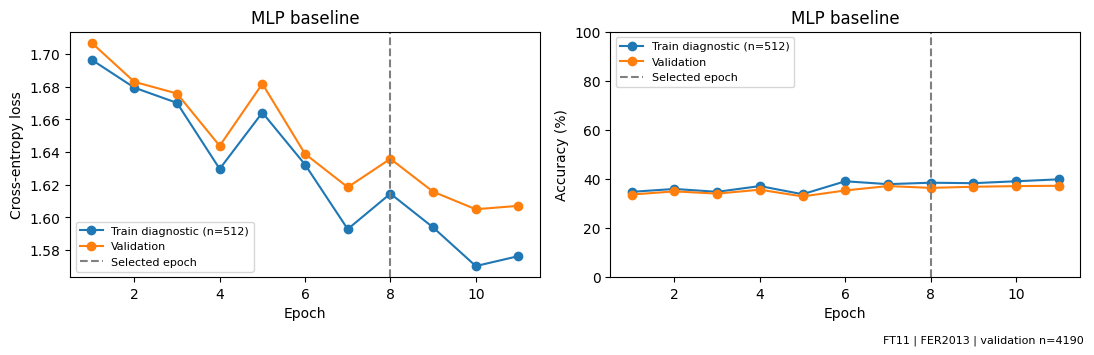

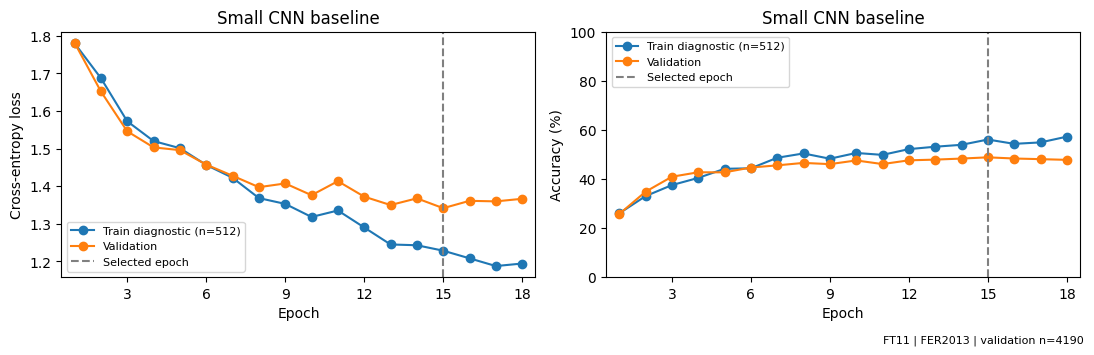

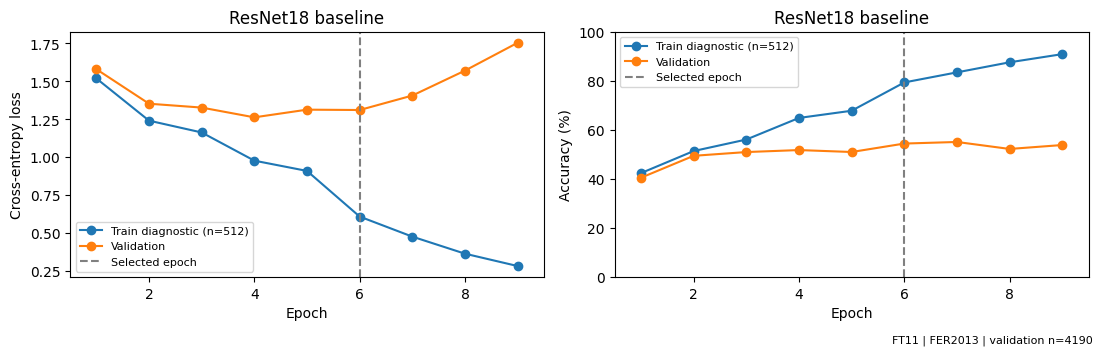

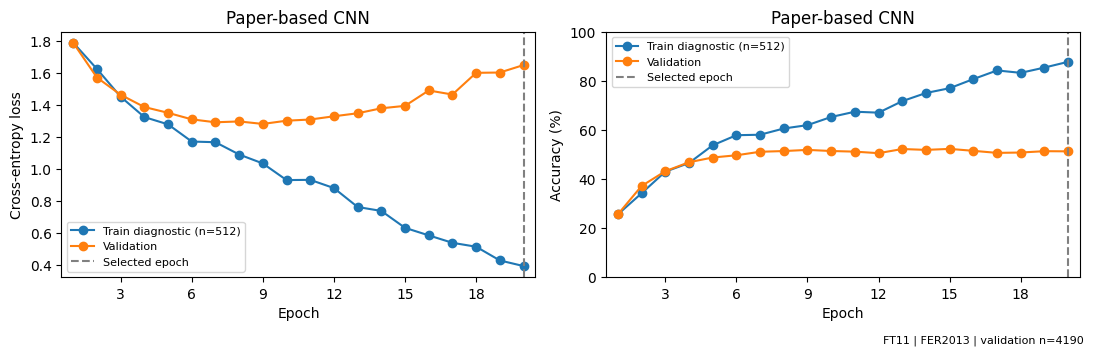

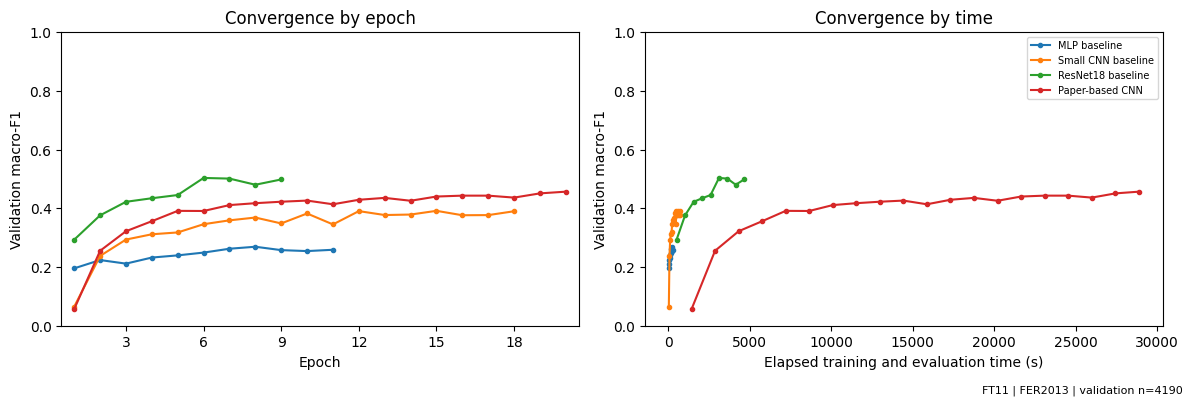

In [12]:
FIGURES = STUDY_DIRECTORY / "figures"
FIGURES.mkdir(exist_ok=True)

def save_figure(fig, name, show=True):
    fig.text(0.99, 0.005, f"FT11 | {DATA_LABEL} | validation n={len(validation_rows)}", ha="right", fontsize=8)
    fig.tight_layout(rect=(0, 0.025, 1, 1))
    fig.savefig(FIGURES / name, dpi=180, bbox_inches="tight")
    if show: plt.show()
    plt.close(fig)

plot_seed = TRAINING_SEEDS[0]
plot_runs = [r for r in completed_runs if r["config"]["seed"] == plot_seed]
for model_id in selected_models:
    group = [r for r in plot_runs if r["config"]["model_id"] == model_id]
    fig, axes = plt.subplots(len(group), 2, figsize=(11, 3.5 * len(group)), squeeze=False, sharex=True, sharey="col")
    max_epoch = max(r["epochs_completed"] for r in group)
    for index, run in enumerate(group):
        epochs = [r["epoch"] for r in run["history"]]
        for axis, key, ylabel, multiplier in ((axes[index, 0], "loss", "Cross-entropy loss", 1),
                                              (axes[index, 1], "accuracy", "Accuracy (%)", 100)):
            for prefix, legend in (("train", f"Train diagnostic (n={len(diagnostic_rows)})"), ("validation", "Validation")):
                axis.plot(epochs, [r[f"{prefix}_{key}"] * multiplier for r in run["history"]], marker="o", label=legend)
            axis.axvline(run["best_epoch"], color="gray", linestyle="--", label="Selected epoch")
            axis.set(xlabel="Epoch", ylabel=ylabel, title=experiment_label(model_id, run["config"]["variant"]))
            from matplotlib.ticker import MaxNLocator
            axis.set_xlim(0.5, max_epoch + 0.5)
            axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True, min_n_ticks=1))
            if key == "accuracy": axis.set_ylim(0, 100)
            axis.legend(fontsize=8)
    save_figure(fig, f"{model_id}_learning_curves.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run in plot_runs:
    label = experiment_label(run["config"]["model_id"], run["config"]["variant"])
    epochs = [r["epoch"] for r in run["history"]]
    axes[0].plot(epochs, [r["validation_macro_f1"] for r in run["history"]], marker=".", label=label)
    elapsed = np.cumsum([r["epoch_seconds"] for r in run["history"]])
    axes[1].plot(elapsed, [r["validation_macro_f1"] for r in run["history"]], marker=".", label=label)
axes[0].set(xlabel="Epoch", ylabel="Validation macro-F1", title="Convergence by epoch", ylim=(0, 1))
axes[0].set_xlim(0.5, max(r["epochs_completed"] for r in plot_runs) + 0.5)
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True, min_n_ticks=1))
axes[1].set(xlabel="Elapsed training and evaluation time (s)", ylabel="Validation macro-F1", title="Convergence by time", ylim=(0, 1))
axes[1].legend(fontsize=7)
save_figure(fig, "convergence.png")


## Training-validation gaps

The loss gap is validation loss minus training-diagnostic loss. The accuracy gap is training-diagnostic accuracy minus validation accuracy, in percentage points. A smaller gap can also occur when a model learns poorly, so check validation macro-F1 and both learning curves.

This cell compares all four methods. The architectures differ in several ways; this experiment cannot isolate a causal effect of dropout. Use the old v5 paired experiment only when discussing that earlier dropout-only test.

Report use: Solutions, evaluation, and discussions / overfitting and limitations. Outputs: `generalization_gaps.png`, `generalization_gap_history.csv`, `generalization_gap_summary.csv`, and all-model loss/accuracy grids.


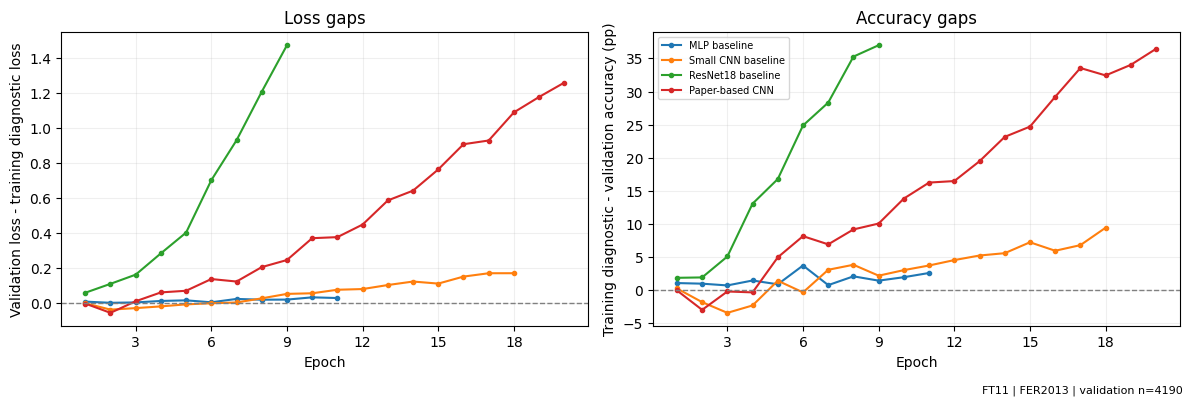

| Method | Best epoch | Completed epochs | Loss gap | Accuracy gap (pp) | Macro-F1 |
|---|---|---|---|---|---|
| MLP baseline | 8 | 11 | +0.0213 | +2.10 | 0.2700 |
| Small CNN baseline | 15 | 18 | +0.1131 | +7.25 | 0.3920 |
| ResNet18 baseline | 6 | 9 | +0.7025 | +24.88 | 0.5037 |
| Paper-based CNN | 20 | 20 | +1.2590 | +36.45 | 0.4571 |

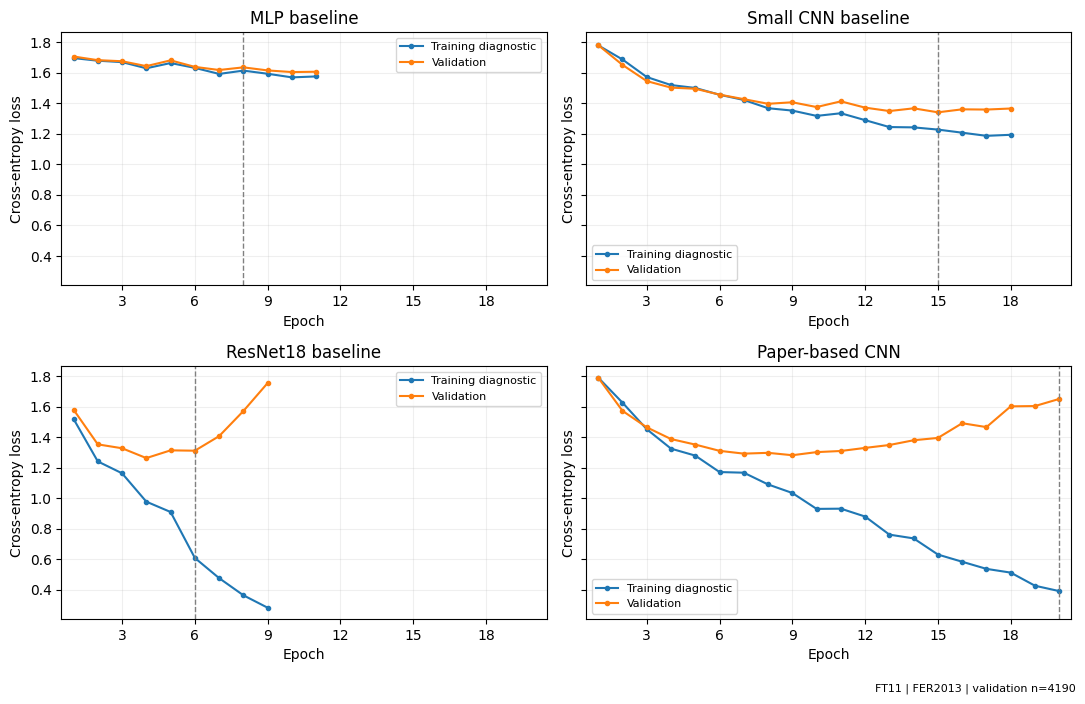

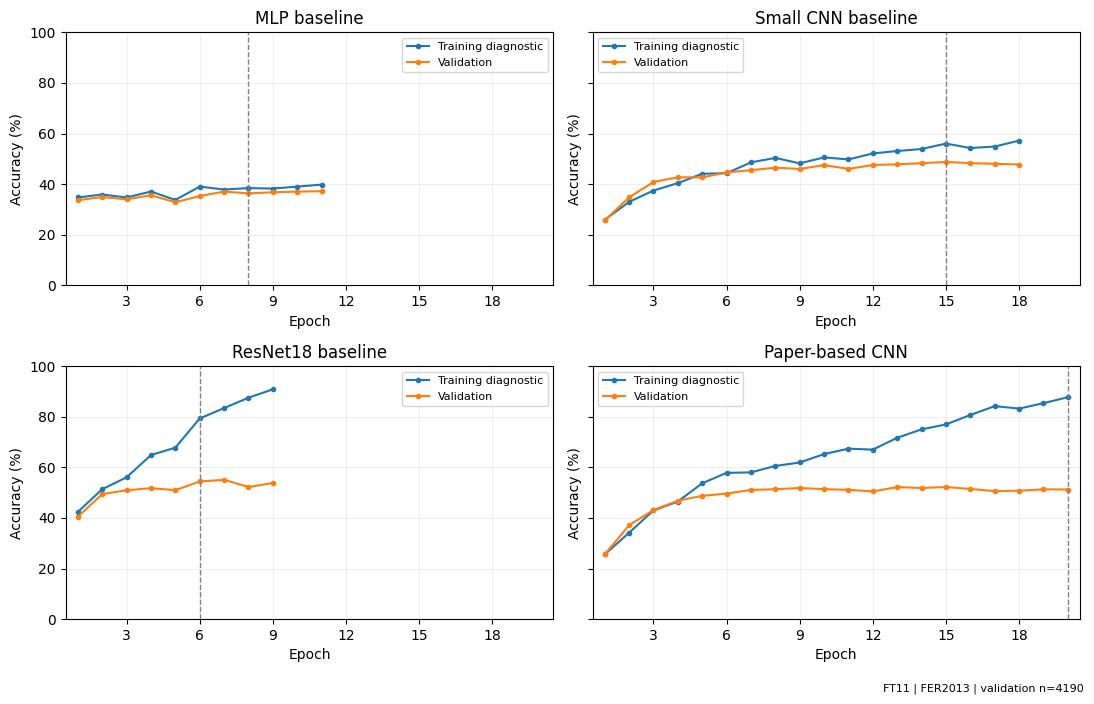

In [13]:
gap_history, gap_summary = [], []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run in plot_runs:
    label = experiment_label(run["config"]["model_id"], run["config"]["variant"])
    group = []
    for row in run["history"]:
        item = {"model": run["config"]["model_id"], "variant": run["config"]["variant"],
                "seed": plot_seed, **row,
                "loss_gap": row["validation_loss"] - row["train_loss"],
                "accuracy_gap_pp": 100 * (row["train_accuracy"] - row["validation_accuracy"])}
        group.append(item)
        gap_history.append(item)
    axes[0].plot([r["epoch"] for r in group], [r["loss_gap"] for r in group], marker=".", label=label)
    axes[1].plot([r["epoch"] for r in group], [r["accuracy_gap_pp"] for r in group], marker=".", label=label)
    gap_summary.append({"model": run["config"]["model_id"], "variant": run["config"]["variant"],
        "seed": plot_seed, "best_epoch": run["best_epoch"], "epochs_completed": run["epochs_completed"],
        "train_diagnostic_loss_at_checkpoint": run["diagnostic"]["loss"],
        "validation_loss_at_checkpoint": run["validation"]["loss"],
        "loss_gap_at_checkpoint": run["validation"]["loss"]-run["diagnostic"]["loss"],
        "accuracy_gap_pp_at_checkpoint": run["gap_percentage_points"],
        "validation_macro_f1": run["validation"]["macro_f1"]})
for axis in axes:
    axis.axhline(0, color="gray", linestyle="--", linewidth=1)
    axis.set_xlabel("Epoch")
    axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True, min_n_ticks=1))
    axis.grid(alpha=0.2)
axes[0].set(ylabel="Validation loss - training diagnostic loss", title="Loss gaps")
axes[1].set(ylabel="Training diagnostic - validation accuracy (pp)", title="Accuracy gaps")
axes[1].legend(fontsize=7)
save_figure(fig, "generalization_gaps.png")
write_csv(STUDY_DIRECTORY / "generalization_gap_history.csv", gap_history)
write_csv(STUDY_DIRECTORY / "generalization_gap_summary.csv", gap_summary)
markdown_table(["Method", "Best epoch", "Completed epochs", "Loss gap", "Accuracy gap (pp)", "Macro-F1"], [
    [experiment_label(r["model"], r["variant"]), r["best_epoch"], r["epochs_completed"],
     f"{r['loss_gap_at_checkpoint']:+.4f}", f"{r['accuracy_gap_pp_at_checkpoint']:+.2f}",
     f"{r['validation_macro_f1']:.4f}"] for r in gap_summary])

for metric, ylabel, filename in (("loss", "Cross-entropy loss", "all_models_loss_curves.png"),
                                  ("accuracy", "Accuracy (%)", "all_models_accuracy_curves.png")):
    rows = math.ceil(len(plot_runs) / 2)
    fig, axes = plt.subplots(rows, 2, figsize=(11, 3.5 * rows), squeeze=False, sharey=True)
    for axis in axes.flat: axis.axis("off")
    for axis, run in zip(axes.flat, plot_runs):
        axis.axis("on")
        epochs = [row["epoch"] for row in run["history"]]
        scale = 100 if metric == "accuracy" else 1
        for prefix, legend in (("train", "Training diagnostic"), ("validation", "Validation")):
            axis.plot(epochs, [row[f"{prefix}_{metric}"] * scale for row in run["history"]], marker=".", label=legend)
        axis.axvline(run["best_epoch"], linestyle="--", color="gray", linewidth=1)
        axis.set(xlabel="Epoch", ylabel=ylabel, title=experiment_label(run["config"]["model_id"], run["config"]["variant"]),
                 xlim=(0.5, max(r["epochs_completed"] for r in plot_runs) + 0.5))
        axis.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True, min_n_ticks=1))
        axis.grid(alpha=0.2)
        axis.legend(fontsize=8)
        if metric == "accuracy": axis.set_ylim(0, 100)
    save_figure(fig, filename)


## Seven-emotion results and confusion matrices

The complete table and heatmap include all seven emotions for every method. A zero-height bar labelled `0.000` is a measured F1 score. An X at zero is not a missing value. Read actual-image counts and predicted-image counts to distinguish a class that is never predicted from wrong predictions of that class.

The highlighted confusion matrix belongs to the model selected using validation macro-F1, with lower loss breaking a tie. Rows are actual labels; columns are predictions. The percentage view divides each row by its actual class count. The all-method F1 chart still includes every model, not just the selected model.

Report use: Solutions, evaluation, and discussions / per-class results and error analysis. Outputs include `per_class_f1_complete.png`, `per_class_f1_comparison.png`, `best_model_confusion.png`, and per-model matrices and CSVs. Choose the heatmap or bar chart according to readability.


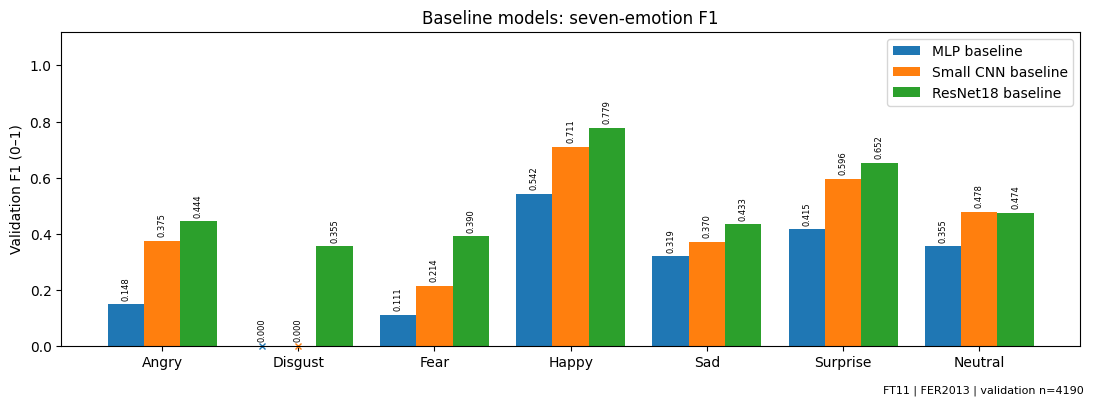

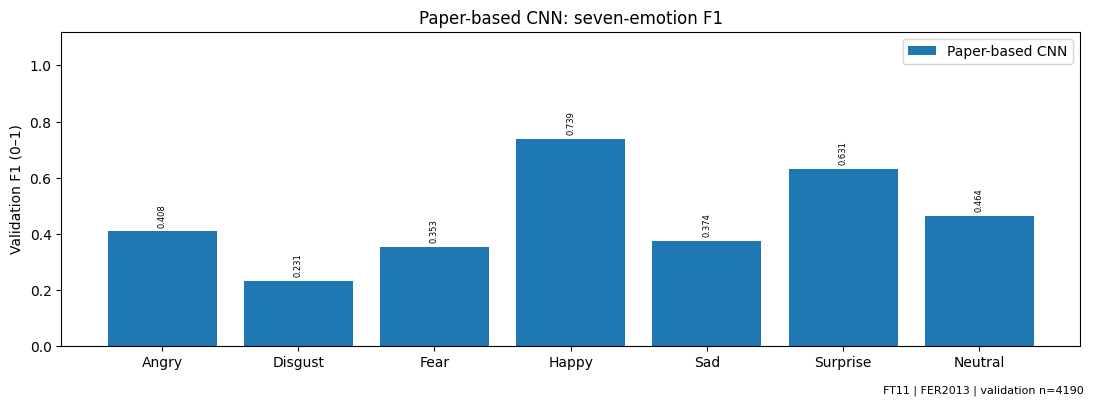

Selected using validation: resnet18 / baseline | displayed seed: 42


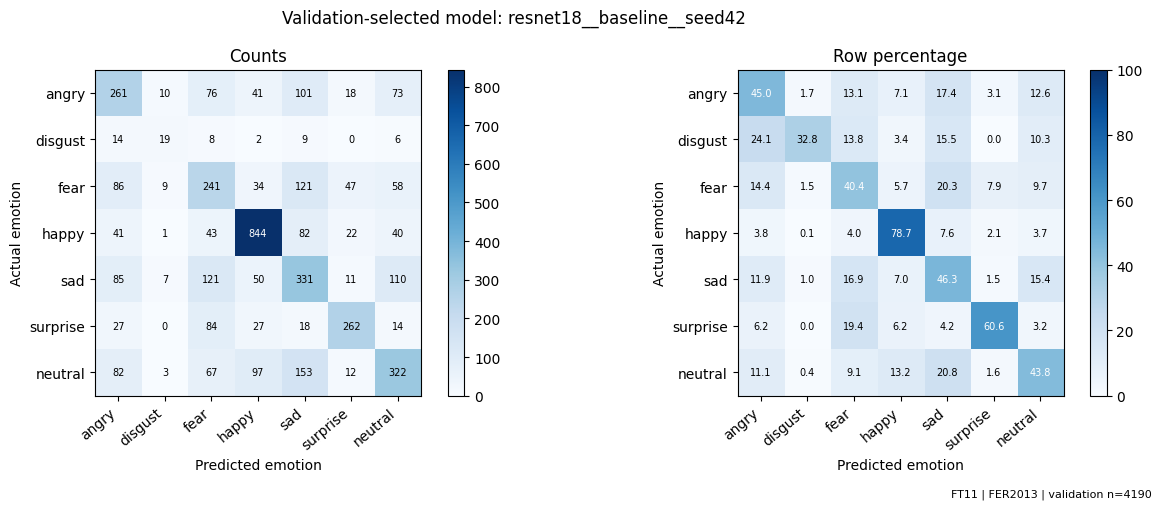

| Emotion | Actual | Predicted | Precision | Recall | F1 |
|---|---|---|---|---|---|
| angry | 580 | 596 | 0.438 | 0.450 | 0.444 |
| disgust | 58 | 49 | 0.388 | 0.328 | 0.355 |
| fear | 596 | 640 | 0.377 | 0.404 | 0.390 |
| happy | 1073 | 1095 | 0.771 | 0.787 | 0.779 |
| sad | 715 | 815 | 0.406 | 0.463 | 0.433 |
| surprise | 432 | 372 | 0.704 | 0.606 | 0.652 |
| neutral | 736 | 623 | 0.517 | 0.438 | 0.474 |

mlp__baseline__seed42 missed every actual example of: disgust
cnn__baseline__seed42 missed every actual example of: disgust


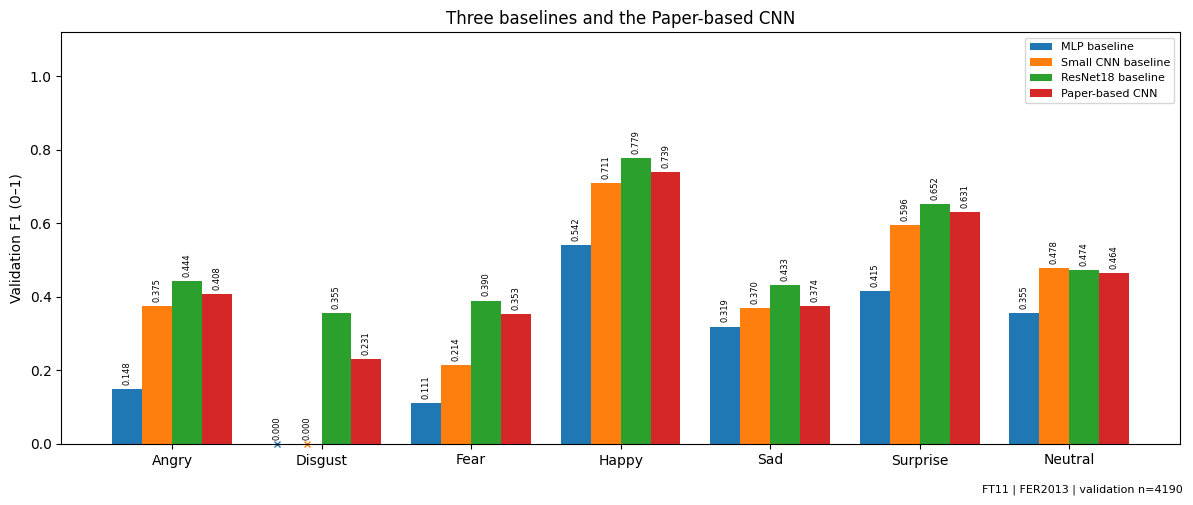

| Emotion | Actual images | MLP baseline | Small CNN baseline | ResNet18 baseline | Paper-based CNN |
|---|---|---|---|---|---|
| angry | 580 | 0.148 | 0.375 | 0.444 | 0.408 |
| disgust | 58 | 0.000 | 0.000 | 0.355 | 0.231 |
| fear | 596 | 0.111 | 0.214 | 0.390 | 0.353 |
| happy | 1073 | 0.542 | 0.711 | 0.779 | 0.739 |
| sad | 715 | 0.319 | 0.370 | 0.433 | 0.374 |
| surprise | 432 | 0.415 | 0.596 | 0.652 | 0.631 |
| neutral | 736 | 0.355 | 0.478 | 0.474 | 0.464 |

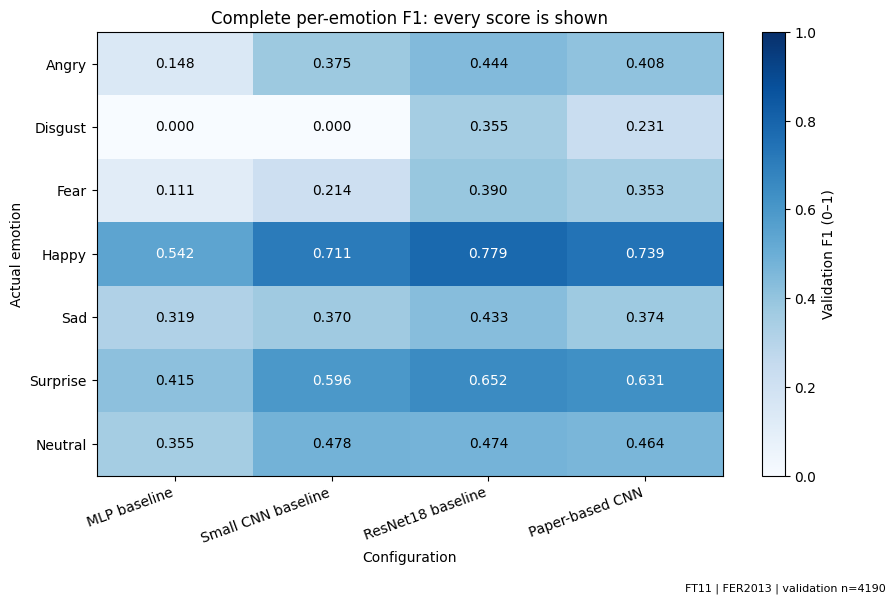

0.000 is a measured score, not an omitted emotion. Read the prediction counts and confusion matrix to identify the errors.


In [14]:
for run in completed_runs:
    metrics = run["validation"]["per_class"]
    if [m["label"] for m in metrics] != list(LABELS):
        raise ValueError("Class metrics are incomplete or out of order. Score all seven labels.")
    if sum(m["support"] for m in metrics) != len(validation_rows):
        raise ValueError("Class support does not match the validation split.")
    if not all(np.isfinite(m["f1"]) and 0 <= m["f1"] <= 1 for m in metrics):
        raise ValueError("A class F1 score is invalid.")

def label_f1_bars(axis, bars, scores):
    axis.bar_label(bars, labels=[f"{score:.3f}" for score in scores], padding=3,
                   fontsize=6, rotation=90)
    for bar, score in zip(bars, scores):
        if score == 0:
            axis.plot(bar.get_x() + bar.get_width()/2, 0, marker="x", color=bar.get_facecolor(),
                      markersize=5, clip_on=False)
    axis.set_ylim(0, 1.12)
    axis.set_yticks(np.arange(0, 1.01, 0.2))

per_class_rows = []
for run in completed_runs:
    for metric in run["validation"]["per_class"]:
        per_class_rows.append({"model": run["config"]["model_id"], "variant": run["config"]["variant"],
                               "seed": run["config"]["seed"], **metric})
write_csv(STUDY_DIRECTORY / "all_per_class_validation.csv", per_class_rows)
for variant in selected_variants:
    fig, axis = plt.subplots(figsize=(11, 4))
    present_models = [model_id for model_id in selected_models if variant in model_variants[model_id]]
    width = 0.8 / len(present_models)
    x = np.arange(len(LABELS))
    for index, model_id in enumerate(present_models):
        group = [r for r in completed_runs if r["config"]["model_id"] == model_id and r["config"]["variant"] == variant]
        values = np.array([[m["f1"] for m in r["validation"]["per_class"]] for r in group])
        errors = values.std(axis=0, ddof=1) if len(group) > 1 else None
        bars = axis.bar(x + (index - (len(present_models)-1)/2) * width, values.mean(axis=0), width,
                        yerr=errors, label=experiment_label(model_id, variant), capsize=3)
        label_f1_bars(axis, bars, values.mean(axis=0))
    axis.set_xticks(x, [label.capitalize() for label in LABELS])
    axis.set(ylabel="Validation F1 (0–1)", title="Paper-based CNN: seven-emotion F1" if variant == "paper_based" else "Baseline models: seven-emotion F1")
    axis.legend()
    save_figure(fig, f"per_class_f1_{variant}.png")

def selection_key(model_id, variant):
    group = [r for r in completed_runs if r["config"]["model_id"] == model_id and r["config"]["variant"] == variant]
    return (statistics.mean(r["validation"]["macro_f1"] for r in group),
            -statistics.mean(r["validation"]["loss"] for r in group))

chosen_variants = {m: max(model_variants[m], key=lambda v: selection_key(m, v)) for m in selected_models}
best_model = max(selected_models, key=lambda m: selection_key(m, chosen_variants[m]))
best_variant = chosen_variants[best_model]
best_run = next(r for r in plot_runs if r["config"]["model_id"] == best_model and r["config"]["variant"] == best_variant)
print("Selected using validation:", best_model, "/", best_variant, "| displayed seed:", plot_seed)

def show_confusion(report, title, filename, show=True):
    matrix = np.asarray(report["confusion_matrix"])
    normalized = np.divide(matrix, matrix.sum(axis=1, keepdims=True),
                           out=np.zeros_like(matrix, dtype=float), where=matrix.sum(axis=1, keepdims=True) != 0)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for axis, values, percent in ((axes[0], matrix, False), (axes[1], normalized * 100, True)):
        im = axis.imshow(values, cmap="Blues", vmin=0, vmax=100 if percent else None)
        axis.set_xticks(range(7), LABELS, rotation=40, ha="right")
        axis.set_yticks(range(7), LABELS)
        axis.set(xlabel="Predicted emotion", ylabel="Actual emotion", title="Row percentage" if percent else "Counts")
        limit = values.max() / 2 if values.size else 0
        for row in range(7):
            for col in range(7):
                label = f"{values[row, col]:.1f}" if percent else str(values[row, col])
                axis.text(col, row, label, ha="center", va="center", fontsize=7,
                          color="white" if values[row, col] > limit else "black")
        fig.colorbar(im, ax=axis, fraction=0.045)
    fig.suptitle(title)
    save_figure(fig, filename, show=show)

for run in plot_runs:
    label = run["run_key"]
    show_confusion(run["validation"], f"Validation: {label}", f"confusion_{label}.png", show=False)
    write_csv(STUDY_DIRECTORY / "models" / label / "confusion_matrix.csv", [
        {"actual": emotion, **dict(zip(LABELS, counts))}
        for emotion, counts in zip(LABELS, run["validation"]["confusion_matrix"])])
show_confusion(best_run["validation"], f"Validation-selected model: {best_run['run_key']}", "best_model_confusion.png")
markdown_table(["Emotion", "Actual", "Predicted", "Precision", "Recall", "F1"], [
    [r["label"], r["support"], r["predicted_count"], f"{r['precision']:.3f}", f"{r['recall']:.3f}", f"{r['f1']:.3f}"]
    for r in best_run["validation"]["per_class"]])
for run in plot_runs:
    weak = [m["label"] for m in run["validation"]["per_class"] if m["support"] and m["recall"] == 0]
    if weak: print(run["run_key"], "missed every actual example of:", ", ".join(weak))

# Compare every method, including the research-based architecture.
experiment_pairs = experiment_plan
fig, axis = plt.subplots(figsize=(12, 5))
width = 0.8 / len(experiment_pairs)
x = np.arange(len(LABELS))
for index, (model_id, variant) in enumerate(experiment_pairs):
    group = [r for r in completed_runs if r["config"]["model_id"] == model_id and r["config"]["variant"] == variant]
    values = np.array([[m["f1"] for m in r["validation"]["per_class"]] for r in group])
    errors = values.std(axis=0, ddof=1) if len(group) > 1 else None
    bars = axis.bar(x + (index - (len(experiment_pairs) - 1) / 2) * width, values.mean(axis=0), width,
                    yerr=errors, capsize=3, label=experiment_label(model_id, variant))
    label_f1_bars(axis, bars, values.mean(axis=0))
axis.set_xticks(x, [emotion.capitalize() for emotion in LABELS])
title = "Three baselines and the Paper-based CNN" if len(experiment_pairs) == 4 else "F1 across tested configurations"
axis.set(ylabel="Validation F1 (0–1)", title=title)
axis.legend(fontsize=8)
save_figure(fig, "per_class_f1_comparison.png")

# A complete numeric view makes a true zero distinct from a missing result.
f1_matrix = np.array([
    [next(r for r in completed_runs if (r["config"]["model_id"], r["config"]["variant"]) == pair)["validation"]["per_class"][i]["f1"]
     for pair in experiment_pairs]
    for i in range(len(LABELS))
])
labels = [experiment_label(*pair) for pair in experiment_pairs]
reference_metrics = completed_runs[0]["validation"]["per_class"]
f1_rows = [{"emotion": emotion, "support": reference_metrics[i]["support"],
            **{label: float(f1_matrix[i, j]) for j, label in enumerate(labels)}}
           for i, emotion in enumerate(LABELS)]
write_csv(STUDY_DIRECTORY / "per_class_f1_complete.csv", f1_rows)
markdown_table(["Emotion", "Actual images", *labels], [
    [r["emotion"], r["support"], *[f"{r[label]:.3f}" for label in labels]] for r in f1_rows])
fig, axis = plt.subplots(figsize=(9, 6))
im = axis.imshow(f1_matrix, cmap="Blues", vmin=0, vmax=1, aspect="auto")
axis.set_xticks(range(len(labels)), labels, rotation=20, ha="right")
axis.set_yticks(range(7), [emotion.capitalize() for emotion in LABELS])
axis.set(title="Complete per-emotion F1: every score is shown", xlabel="Configuration", ylabel="Actual emotion")
for i in range(7):
    for j in range(len(labels)):
        axis.text(j, i, f"{f1_matrix[i, j]:.3f}", ha="center", va="center",
                  color="white" if f1_matrix[i, j] > 0.5 else "black")
fig.colorbar(im, ax=axis, label="Validation F1 (0–1)")
save_figure(fig, "per_class_f1_complete.png")
if np.any(f1_matrix == 0):
    print("0.000 is a measured score, not an omitted emotion. Read the prediction counts and confusion matrix to identify the errors.")

## Speed and quality

`speed_accuracy_tradeoff.png` shows batch-1 prediction latency versus validation accuracy, and total training/evaluation time versus validation macro-F1. State the device and timing scope when using it. Different stopping epochs affect total training time.

The benchmark excludes image loading and preprocessing. It does not measure a webcam or deployed application. One timing session cannot establish hardware-independent speed.

Report use: Solutions, evaluation, and discussions / computational trade-offs. Read the chart with parameter counts, mean epoch time, and batch-64 throughput.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for run in plot_runs:
    label = experiment_label(run["config"]["model_id"], run["config"]["variant"])
    x = run["speed"]["latency_ms_batch1"]
    y = run["validation"]["accuracy"] * 100
    color = {"mlp": "tab:blue", "cnn": "tab:orange", "resnet18": "tab:green", "paper_cnn": "tab:red"}[run["config"]["model_id"]]
    marker = "o" if run["config"]["variant"] == "baseline" else "^"
    axes[0].scatter(x, y, s=70, color=color, marker=marker, label=label)
    x2, y2 = run["training_seconds"], run["validation"]["macro_f1"]
    axes[1].scatter(x2, y2, s=70, color=color, marker=marker)
axes[0].set(xlabel="Median prediction latency, batch 1 (ms)", ylabel="Validation accuracy (%)", title=f"Prediction trade-off on {DEVICE}")
axes[1].set(xlabel="Training + diagnostic + validation time (s)", ylabel="Validation macro-F1", title="Training cost trade-off")
axes[0].legend(fontsize=8)
save_figure(fig, "speed_accuracy_tradeoff.png")
markdown_table(["Run", "Batch-1 latency (ms)", "Batch-1 p95 (ms)", "Batch size", "Images/s"], [
    [r["run_key"], f"{r['speed']['latency_ms_batch1']:.3f}", f"{r['speed']['latency_p95_ms_batch1']:.3f}",
     r["speed"]["batch_size"], f"{r['speed']['throughput_images_per_second']:.1f}"] for r in plot_runs])

## Measured comparison with the paper-based method

Rank the four methods using the actual validation scores. The comparison also shows model size, checkpoint size and time. No method is assumed to win.

`paper_vs_baselines.csv` compares the Paper-based CNN against each baseline. A positive F1 difference favours the Paper-based CNN for this run; a negative difference favours the baseline. Multiple architectural changes prevent attributing a difference to one layer or dropout alone.

Report use: Solutions, evaluation, and discussions / comparison and limitations. Use the observations as evidence for the team's own conclusion. One seed does not estimate repeat-run variation, and the paper's 61.7% test accuracy is not an FT11 result.


In [ ]:
ranked_experiments = []
for model_id in selected_models:
    for variant in model_variants[model_id]:
        group = [r for r in completed_runs if r["config"]["model_id"] == model_id and r["config"]["variant"] == variant]
        ranked_experiments.append({
            "model": model_id, "variant": variant, "label": experiment_label(model_id, variant),
            "seeds": len(group),
            "mean_macro_f1": statistics.mean(r["validation"]["macro_f1"] for r in group),
            "mean_validation_loss": statistics.mean(r["validation"]["loss"] for r in group),
            "mean_accuracy_percent": statistics.mean(r["validation"]["accuracy"] * 100 for r in group),
            "parameters_millions": group[0]["parameters"] / 1_000_000,
            "mean_checkpoint_mib": statistics.mean((STUDY_DIRECTORY / r["checkpoint_relative_path"]).stat().st_size / (1024**2) for r in group),
            "mean_training_minutes": statistics.mean(r["training_seconds"] / 60 for r in group),
            "mean_latency_ms": statistics.mean(r["speed"]["latency_ms_batch1"] for r in group),
            "mean_images_per_second": statistics.mean(r["speed"]["throughput_images_per_second"] for r in group),
        })
ranked_experiments.sort(key=lambda r: (-r["mean_macro_f1"], r["mean_validation_loss"]))
write_csv(STUDY_DIRECTORY / "overall_performance.csv", ranked_experiments)
markdown_table(["Configuration", "Accuracy (%)", "Macro-F1", "Parameters (M)", "Checkpoint (MiB)", "Train (min)", "Latency (ms)"], [
    [r["label"], f"{r['mean_accuracy_percent']:.2f}", f"{r['mean_macro_f1']:.4f}",
     f"{r['parameters_millions']:.3f}", f"{r['mean_checkpoint_mib']:.3f}",
     f"{r['mean_training_minutes']:.2f}", f"{r['mean_latency_ms']:.3f}"] for r in ranked_experiments])
f1_winner = ranked_experiments[0]
accuracy_winner = max(ranked_experiments, key=lambda r: r["mean_accuracy_percent"])
speed_winner = min(ranked_experiments, key=lambda r: r["mean_latency_ms"])
paper_result = next(r for r in ranked_experiments if r["model"] == "paper_cnn")
paper_vs_baselines = []
for baseline in (r for r in ranked_experiments if r["model"] in BASELINE_MODEL_IDS):
    delta = paper_result["mean_macro_f1"] - baseline["mean_macro_f1"]
    paper_vs_baselines.append({"baseline": baseline["label"],
        "paper_macro_f1": paper_result["mean_macro_f1"], "baseline_macro_f1": baseline["mean_macro_f1"],
        "macro_f1_difference": delta,
        "accuracy_difference_pp": paper_result["mean_accuracy_percent"]-baseline["mean_accuracy_percent"],
        "outcome": "higher" if delta > 0 else "lower" if delta < 0 else "equal"})
write_csv(STUDY_DIRECTORY / "paper_vs_baselines.csv", paper_vs_baselines)
markdown_table(["Paper-based CNN compared with", "Macro-F1 difference", "Accuracy difference (pp)", "Outcome"], [
    [r["baseline"], f"{r['macro_f1_difference']:+.4f}", f"{r['accuracy_difference_pp']:+.2f}", r["outcome"]]
    for r in paper_vs_baselines])
print("Measured observations for these validation experiments:")
print(f"Highest macro-F1: {f1_winner['label']} ({f1_winner['mean_macro_f1']:.4f}).")
print(f"Highest accuracy: {accuracy_winner['label']} ({accuracy_winner['mean_accuracy_percent']:.2f}%).")
print(f"Lowest measured batch-1 latency: {speed_winner['label']} ({speed_winner['mean_latency_ms']:.3f} ms).")
if len(TRAINING_SEEDS) == 1:
    print("One training seed was used; repeat-run variation is not estimated.")
write_json(STUDY_DIRECTORY / "measured_conclusion.json", {
    "evaluation_split": "validation",
    "highest_macro_f1": f1_winner, "highest_accuracy": accuracy_winner,
    "lowest_latency": speed_winner, "paper_method_comparisons": paper_vs_baselines,
    "limits": ["Paper-based CNN uses FT11 shared training choices; it is not an exact paper reproduction.",
               "A smaller training-validation gap alone does not establish reduced overfitting.",
               "Single-seed results do not estimate repeat-run variation."],
})


## Correct and incorrect examples

This panel takes the first four correct and first four wrong entries from the selected model's validation predictions. File order can place all examples in one emotion. The panel is a selected illustration, not a representative sample or an estimate of accuracy.

Use the confusion matrix to identify error pairs. Check the visible images before proposing a cause such as pose, lighting or occlusion. Scores from expression labels do not establish a person's internal emotional state.

Report use: Solutions, evaluation, and discussions / difficult cases. Output: `validation_examples.png`.


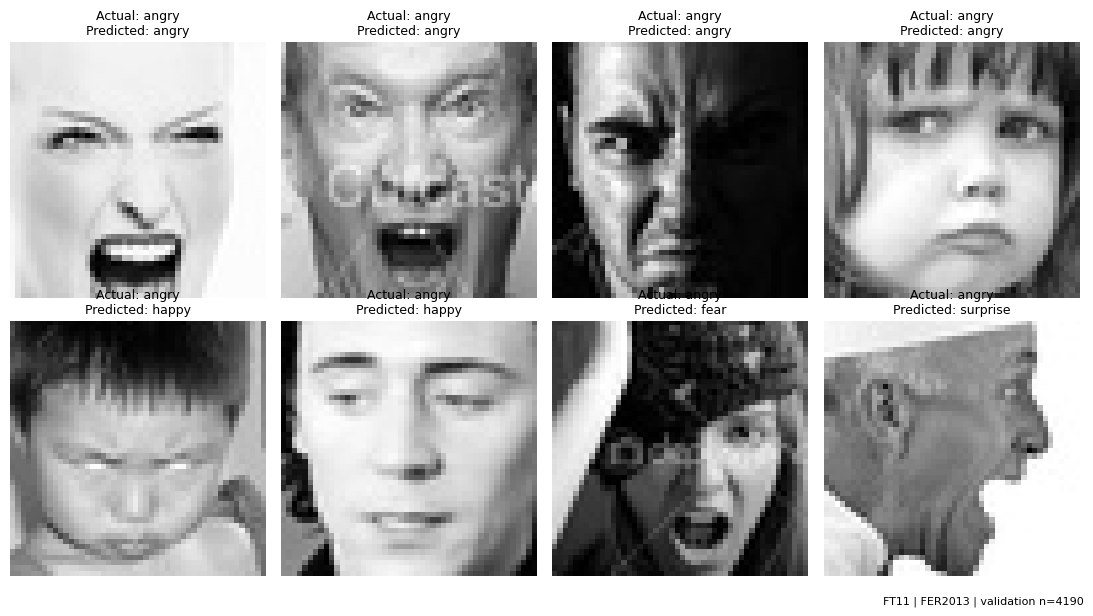

In [17]:
prediction_path = STUDY_DIRECTORY / "models" / best_run["run_key"] / "validation_predictions.csv"
with prediction_path.open() as handle:
    predictions = list(csv.DictReader(handle))
correct = [r for r in predictions if r["actual"] == r["predicted"]][:4]
incorrect = [r for r in predictions if r["actual"] != r["predicted"]][:4]
examples = correct + incorrect
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for axis in axes.flat: axis.axis("off")
for axis, row in zip(axes.flat, examples):
    with Image.open(TRAIN_DIR / row["relative_path"]) as image:
        axis.imshow(image.convert("L"), cmap="gray")
    axis.set_title(f"Actual: {row['actual']}\nPredicted: {row['predicted']}", fontsize=9)
save_figure(fig, "validation_examples.png")

## Difficult cases

For this analysis, review misclassified validation images, low-recall classes, and the most frequent wrong emotion pairs. These are operational definitions based on saved predictions. A class-level table does not prove an image lies near a decision boundary.

Separate measured facts from explanations that remain hypotheses. For example, class imbalance is measured by counts; its causal effect requires another controlled experiment. Confirm pose or occlusion claims by inspecting the images.

Report use: Solutions, evaluation, and discussions / marginal cases and limitations. Outputs: `marginal_case_classes.csv` and `most_frequent_confusions.csv`.


In [ ]:
difficult_classes = sorted(best_run["validation"]["per_class"], key=lambda row: (row["recall"], row["support"]))
write_csv(STUDY_DIRECTORY / "marginal_case_classes.csv", difficult_classes)
matrix = np.asarray(best_run["validation"]["confusion_matrix"])
confused_pairs = sorted([
    {"actual": LABELS[i], "predicted": LABELS[j], "count": int(matrix[i, j])}
    for i in range(7) for j in range(7) if i != j and matrix[i, j] > 0
], key=lambda row: -row["count"])
write_csv(STUDY_DIRECTORY / "most_frequent_confusions.csv", confused_pairs,
          fields=["actual", "predicted", "count"])
markdown_table(["Emotion", "Actual images", "Recall", "F1"], [
    [row["label"], row["support"], f"{row['recall']:.3f}", f"{row['f1']:.3f}"] for row in difficult_classes])
markdown_table(["Actual emotion", "Wrong prediction", "Number of images"], [
    [row["actual"], row["predicted"], row["count"]] for row in confused_pairs[:5]])

## Evidence for the report

| Report section | Notebook material | Team work |
|---|---|---|
| Introduction | FER2013 source, seven labels, class counts and sample images | Explain the problem and relevant applications with citations. |
| Background theory | Model shapes, parameter formulas, loss, gradients and residual connections | Explain the mathematics and lecture links. |
| Solutions | Four model definitions, paper adaptation record and settings | Explain why the designs differ and identify shared training choices. |
| Evaluation and discussions | Comparison table, convergence, class F1, matrices, gaps and speed | State the split, hardware and limitations; explain the observed differences. |
| Conclusion | Measured observations and difficult cases | Reflect on what the team learned and which explanations remain untested. |
| References and acknowledge | Paper DOI, dataset and course sources | Use one reference style, record actual contributions and disclose AI support. |

Choose a few figures that support the report's argument. Several charts show the same values in different forms. More charts do not replace an explanation.


## Project requirement check

The tutor's consolidated requirement governs method selection. MLP, small CNN and ResNet18 remain reference methods; the Paper-based CNN implements a further research-based design. The old dropout-only change is a supporting tuning experiment, not another method.

The main method source is Singh and Nasoz (2020), a published IEEE conference paper with a DOI. Each member should read the method and limitations and be able to explain FT11's adaptations. Support the other designs with appropriate course and research references.

The full project still includes an informative title, introduction, background theory, solutions/evaluation/discussion, a group reflection, actual contribution records and references. The supplied instructions set an eight-page report limit excluding references/appendix and require mathematical reasoning, marginal cases and lecture links. The team must also prepare slides/video, presentation contribution records and Q&A. Confirm the current timing and six-member template with the tutor or Moodle where the supplied documents conflict.

Online resources and AI can support learning. The team remains responsible for understanding and explaining the code and evidence. Follow the supplied disclosure and writing instructions when preparing the assessed report.


## Final test after model choices are fixed

Keep `RUN_FINAL_TEST = False` while changing settings. After the team fixes its choices, set it to `True` and run this scoring cell. It loads the validation-selected checkpoint for each method and performs no weight updates. An existing final-test record is loaded without rescoring.

Keep validation and test scores separately labelled. Do not choose new settings from the test results. Report use: Evaluation / final held-out comparison, once it has actually been run.


In [19]:
final_path = STUDY_DIRECTORY / "final_test_results.json"
final_test_results = json.loads(final_path.read_text())["runs"] if final_path.exists() else []
if RUN_FINAL_TEST:
    if STUDY_CONFIG["train_records"] != manifest["counts"]["train"]["records"]:
        raise ValueError("Finish training on all eligible training images before final test evaluation.")
    if final_path.exists():
        final_test_results = json.loads(final_path.read_text())["runs"]
        print("Final test already recorded. Loaded its saved results without rescoring.")
    else:
        for run in completed_runs:
            cfg = run["config"]
            if cfg["variant"] != chosen_variants[cfg["model_id"]]: continue
            saved = torch.load(STUDY_DIRECTORY / run["checkpoint_relative_path"], map_location="cpu", weights_only=True)
            if saved["label_order"] != list(LABELS) or saved["split_fingerprint"] != SPLIT_ASSIGNMENT_FINGERPRINT:
                raise ValueError("Checkpoint labels or split do not match.")
            model = make_model(cfg["model_id"], cfg).to(DEVICE)
            model.load_state_dict(saved["model_state_dict"])  # Frozen weights; there is no optimizer here.
            test_rows = [r for r in manifest["records"] if r["split"] == "test"]
            metrics = evaluate_model(model, make_loader(test_rows, cfg))
            final_test_results.append({"model": cfg["model_id"], "variant": cfg["variant"], "seed": cfg["seed"], "metrics": metrics})
            del model
        write_json(final_path, {"selection_basis": "validation only", "selected_winner": best_model,
                                "chosen_variants": chosen_variants, "runs": final_test_results})
    markdown_table(["Model", "Variant", "Seed", "Test accuracy (%)", "Test macro-F1"], [
        [r["model"], r["variant"], r["seed"], f"{r['metrics']['accuracy'] * 100:.2f}", f"{r['metrics']['macro_f1']:.4f}"]
        for r in final_test_results])
    write_csv(STUDY_DIRECTORY / "final_test_comparison.csv", [
        {"model": r["model"], "variant": r["variant"], "seed": r["seed"],
         "accuracy_percent": r["metrics"]["accuracy"] * 100,
         "macro_f1": r["metrics"]["macro_f1"], "loss": r["metrics"]["loss"]}
        for r in final_test_results])
    write_csv(STUDY_DIRECTORY / "final_test_per_class.csv", [
        {"model": r["model"], "variant": r["variant"], "seed": r["seed"], **metric}
        for r in final_test_results for metric in r["metrics"]["per_class"]])
else:
    print("Current charts and tables show validation results. Final test record:", "saved" if final_test_results else "not scored")

Current charts and tables show validation results. Final test record: not scored


## Save the evidence

The ZIP contains figures, exact settings, architecture text, histories, predictions, checkpoints, split records and checksums. `paper_method.json` records the paper, Figure 4 design and FT11 adaptations. It excludes the source image folders. Download the ZIP and save the executed notebook beside it.

The revision and code-template hash distinguish this four-method study from v5. Earlier results stay historical. New Paper-based CNN scores exist only after the revised training cell has run. Local VS Code pipeline sync remains a separate task after model choices are fixed.

Report use: Appendix / reproducibility and experiment records.


In [20]:
import zipfile

environment = {
    "python": platform.python_version(), "torch": torch.__version__, "torchvision": torchvision.__version__,
    "numpy": np.__version__, "pillow": PIL.__version__, "matplotlib": matplotlib.__version__,
    "device": str(DEVICE), "device_name": torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else platform.processor(),
    "cuda": torch.version.cuda, "torch_threads": torch.get_num_threads(),
    "platform": platform.platform(),
}
write_json(STUDY_DIRECTORY / "environment.json", environment)
write_json(STUDY_DIRECTORY / "notebook_identity.json", {
    "file": NOTEBOOK_FILE, "revision": NOTEBOOK_REVISION,
    "baseline_template_sha256": NOTEBOOK_TEMPLATE_SOURCE_SHA256,
    "scope": "SHA-256 of delivered code cells with the digest literal replaced by 64 zeros; not a live hash of Colab edits",
})
write_json(STUDY_DIRECTORY / "label_order.json", list(LABELS))
write_json(STUDY_DIRECTORY / "selection.json", {"basis": "mean validation macro-F1; lower mean validation loss tie break",
    "chosen_variants": chosen_variants, "best_model": best_model, "matrix_seed": plot_seed})
log_path = OUTPUT_BASE / DATA_FINGERPRINT / "experiment_log.jsonl"
existing = [json.loads(line) for line in log_path.read_text().splitlines() if line.strip()] if log_path.exists() else []
new_rows = [{**comparison_record(run), "study_id": RUN_ID, "run_key": run["run_key"],
             "experiment_name": EXPERIMENT_NAME, "run_mode": "full", "notebook_revision": NOTEBOOK_REVISION,
             "data_fingerprint": DATA_FINGERPRINT, "split_fingerprint": SPLIT_ASSIGNMENT_FINGERPRINT,
             "train_subset_fingerprint": TRAIN_SUBSET_FINGERPRINT,
             "validation_subset_fingerprint": VALIDATION_SUBSET_FINGERPRINT,
             "diagnostic_subset_fingerprint": DIAGNOSTIC_SUBSET_FINGERPRINT,
             "full_config": run["config"]} for run in completed_runs]
by_id = {(row.get("study_id"), row.get("run_key")): row for row in existing + new_rows}
log_rows = list(by_id.values())
log_path.write_text("".join(json.dumps(row, sort_keys=True) + "\n" for row in log_rows))
(STUDY_DIRECTORY / "experiment_log.jsonl").write_text("".join(json.dumps(row, sort_keys=True) + "\n" for row in log_rows))
comparable = [r for r in log_rows if r.get("study_id") != RUN_ID and r.get("run_mode") == "full"
              and r.get("notebook_revision") == NOTEBOOK_REVISION
              and r.get("split_fingerprint") == SPLIT_ASSIGNMENT_FINGERPRINT
              and r.get("train_subset_fingerprint") == TRAIN_SUBSET_FINGERPRINT
              and r.get("validation_subset_fingerprint") == VALIDATION_SUBSET_FINGERPRINT
              and r.get("diagnostic_subset_fingerprint") == DIAGNOSTIC_SUBSET_FINGERPRINT]
if comparable:
    print("Earlier runs with the same split and selected rows (check settings before comparing):")
    markdown_table(["Experiment", "Model", "Variant", "Seed", "LR", "Batch", "Macro-F1"], [
        [r["experiment_name"], r["model"], r["variant"], r["seed"], r["learning_rate"], r["batch_size"],
         f"{r['validation_macro_f1']:.4f}"] for r in comparable])
write_json(STUDY_DIRECTORY / "test_status.json", {
    "source_test_evaluated": bool(final_test_results), "run_mode": "full",
})
checksums_path = STUDY_DIRECTORY / "checksums.sha256"
bundle_files = [p for p in sorted(STUDY_DIRECTORY.rglob("*"))
                if p.is_file() and p != checksums_path and p.suffix not in {".zip", ".sha256"}]
unexpected_images = [p for p in bundle_files if p.suffix.lower() in IMAGE_EXTENSIONS and p.parent != FIGURES]
if unexpected_images:
    raise ValueError(f"Unexpected source image in export: {unexpected_images[0]}")
checksums_path.write_text("".join(f"{hashlib.sha256(p.read_bytes()).hexdigest()}  {p.relative_to(STUDY_DIRECTORY).as_posix()}\n" for p in bundle_files))
ZIP_PATH = STUDY_DIRECTORY / f"{RUN_ID}_bundle.zip"
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for p in bundle_files + [checksums_path]:
        archive.write(p, p.relative_to(STUDY_DIRECTORY))
digest = hashlib.sha256(ZIP_PATH.read_bytes()).hexdigest()
ZIP_PATH.with_suffix(".zip.sha256").write_text(f"{digest}  {ZIP_PATH.name}\n")
print("Download:", ZIP_PATH)
print("ZIP SHA-256:", digest)
if IN_COLAB:
    from google.colab import files
    files.download(str(ZIP_PATH))

Download: /content/fer2013_colab_runs/d67be25b0158b2017c0f4ad4eca68b8632bd9ec66bb579cf2de8224fe1eabf82/studies/20261031T181704Z_bcbd93/20261031T181704Z_bcbd93_bundle.zip
ZIP SHA-256: 234957f5155ebad3e060b0013913a683f25009dd7c9bd009a38619dc8c5169db


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sources

- Main method: Singh, S., and Nasoz, F. (2020). *Facial expression recognition with convolutional neural networks*. IEEE CCWC, pp. 324-328. DOI: [10.1109/CCWC47524.2020.9031283](https://doi.org/10.1109/CCWC47524.2020.9031283). Architecture: Figure 4, PDF p3 / printed p326. The group's local PDF is in DOI/Natalie.
- Published record: [UNLV university repository](https://oasis.library.unlv.edu/compsci_fac_articles/175/). Read the full paper, not only this notebook's summary.
- Supporting FER survey: Li and Deng, *Deep facial expression recognition: A survey*, DOI [10.1109/TAFFC.2020.2981446](https://doi.org/10.1109/TAFFC.2020.2981446). Distinguish the local arXiv version from the journal version when citing it.
- Residual architecture: He et al., *Deep residual learning for image recognition*, CVPR 2016; [conference paper](https://www.cv-foundation.org/openaccess/content_cvpr_2016/papers/He_Deep_Residual_Learning_CVPR_2016_paper.pdf).
- Course: Lecture 2, Lab 1 and Lab 2. The exact FT11 architectures and training settings are project choices.
- Data: [FER2013 image folders](https://www.kaggle.com/datasets/msambare/fer2013). Dataset paper: Goodfellow et al. (2013), [DOI 10.1007/978-3-642-42051-1_16](https://doi.org/10.1007/978-3-642-42051-1_16). A dataset paper is additional to the method article.
- Assignment: the tutor's consolidated three-method message, Project Instruction.pdf and the supplied report/presentation guides.

FT11's measurements come from its own saved runs. The paper's score and other groups' examples are not FT11 results. Codex assisted with code and explanation editing; the team must check the work and record AI use under the course instructions.
